# Examen Parcial - Informe 02 - Redes Neuronales y Aprendizaje Profundo - Grupo 07
---
**Crisanto Palacios, Eduardo**
**Riveros Ruiz, Jason Wilmer**
**Torres Vela, Juan Carlos (Representante)**
**Zavala Suyo, Rafael**

---
**Prof. Dr.    Aldo Camargo**

---

# 02 · Entrenamiento U-Net / Attention U-Net: ¿cómo combinar etiquetas doradas y débiles?

**Pregunta de investigación:** con 252 chips dorados (train) y miles de chips con etiqueta Otsu ruidosa, ¿qué estrategia de supervisión generaliza mejor?

| Experimento | Estrategia |
|---|---|
| **E1** | Solo etiquetas doradas |
| **E2** | Solo etiquetas débiles (Otsu-S1) |
| **E3** | Pre-entrenar con débiles → *fine-tuning* con doradas |
| **E4** | Mixta: muestreo 50/50 dorada/débil, con la etiqueta débil ponderada en la pérdida (`WEAK_W`) |
| **E5** | **Attention U-Net** con la mejor estrategia de E1–E4 |

**Protocolo (evita fuga de información):** la mejor configuración se elige con la partición **validación**; *test* y **Bolivia** (evento nunca visto) solo se reportan.  

Métricas: IoU global, IoU medio por chip (como Sen1Floods11), omisión y comisión. La pérdida ignora los píxeles `-1` (sin dato).

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!pip -q install rasterio
import sys, os, json, importlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
BASE = '/content/drive/MyDrive/Dagua'
sys.path.insert(0, f'{BASE}/code')
import flood_utils as fu
importlib.reload(fu)
from flood_utils import *
CKPT, RES = f'{BASE}/checkpoints', f'{BASE}/results'
os.makedirs(CKPT, exist_ok=True); os.makedirs(RES, exist_ok=True)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device, torch.cuda.get_device_name(0) if device.type == 'cuda' else '')
set_seed(42)

Mounted at /content/drive
cuda Tesla T4


In [ ]:
N_WEAK = None                       # debe coincidir con el notebook 01 (None = todos, ~4400 chips)
download_sen1floods11(n_weak=N_WEAK)   # no repite lo ya descargado
sp = load_hand_splits()
excl = {chip_id(it['name']) for v in sp.values() for it in v}
weak = load_weak_items(excl)
print({k: len(v) for k, v in sp.items()}, '| débiles:', len(weak))

def make_loader(items, bs=8):
    return DataLoader(FloodDataset(items), batch_size=bs, shuffle=False, num_workers=2)
val_loader, test_loader, bol_loader = (make_loader(sp[k]) for k in ('val', 'test', 'bolivia'))
x, y, v, w, _ = FloodDataset(sp['train'], crop=256, augment=True)[0]
print('muestra:', x.shape, y.shape, v.shape, float(w))

$ gsutil -m -q rsync -r gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand /content/sen1floods11/HandLabeled/S1Hand
$ gsutil -m -q rsync -r gs://sen1floods11/v1.1/data/flood_events/HandLabeled/LabelHand /content/sen1floods11/HandLabeled/LabelHand
$ gsutil -m -q rsync -r gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1OtsuLabelHand /content/sen1floods11/HandLabeled/S1OtsuLabelHand
$ gsutil -m -q cp -r gs://sen1floods11/v1.1/splits/flood_handlabeled /content/sen1floods11/splits/
$ cat /content/_lab.txt | gsutil -m -q cp -I /content/sen1floods11/WeaklyLabeled/S1OtsuLabelWeak/
$ cat /content/_s1.txt | gsutil -m -q cp -I /content/sen1floods11/WeaklyLabeled/S1Weak/
Chips débiles disponibles: 2
{'train': 252, 'val': 89, 'test': 90, 'bolivia': 15} | débiles: 2
muestra: torch.Size([2, 256, 256]) torch.Size([1, 256, 256]) torch.Size([1, 256, 256]) 1.0


## Hiperparámetros
Ajusta las épocas según el tiempo de Colab. Con T4 y `N_WEAK=2000`, la configuración por defecto toma del orden de 30-60 min en total.

In [ ]:
CROP     = 256     # recorte aleatorio de entrenamiento (la evaluación usa chips completos de 512)
EP_HAND  = 60      # E1
EP_WEAK  = 12      # E2 (cada época recorre todos los chips débiles)
EP_FT    = 40      # E3 etapa 2 (fine-tuning)
EP_MIX   = 20      # E4 / E5-mixta
MIX_N    = 1000    # muestras por época en la estrategia mixta
WEAK_W   = 0.5     # peso de la pérdida de chips débiles en la estrategia mixta
RETRAIN  = False   # True = reentrena aunque exista el checkpoint
MIN_WEAK = 100     # mínimo de chips débiles para E2/E3/E4. Con bs=8 y drop_last=True, <8 chips => 0 lotes => total_steps=0 (error)

import subprocess, shutil
GCS_WK = 'gs://sen1floods11/v1.1/data/flood_events/WeaklyLabeled'

def _gs_ls(path):
    r = subprocess.run(['gsutil', 'ls', path], capture_output=True, text=True)
    if r.returncode != 0:
        print('[ERROR gsutil ls]', r.stderr.strip()[-500:])
    return [l.strip() for l in r.stdout.splitlines() if l.strip().endswith('.tif')]

def fetch_weak(n=None, workers=16, retries=3):
    """Descarga chips débiles (S1Weak + S1OtsuLabelWeak) EMPAREJADOS por HTTPS en paralelo (el bucket es público).
    Se evita `gsutil cp -I` (con -m solo copiaba ~2 archivos por lote sin dar error). Incremental y con verificación."""
    import requests
    from concurrent.futures import ThreadPoolExecutor, as_completed
    wk = f'{LOCAL}/WeaklyLabeled'
    d_s1, d_lb = f'{wk}/S1Weak', f'{wk}/S1OtsuLabelWeak'
    os.makedirs(d_s1, exist_ok=True); os.makedirs(d_lb, exist_ok=True)
    key = lambda u: os.path.basename(u).rsplit('_', 1)[0]          # 'Ghana_103272_S1Weak.tif' -> 'Ghana_103272'
    s1 = {key(u): u for u in _gs_ls(f'{GCS_WK}/S1Weak/')}
    lb = {key(u): u for u in _gs_ls(f'{GCS_WK}/S1OtsuLabelWeak/')}
    keys = sorted(set(s1) & set(lb))
    print(f'Chips débiles listados en el bucket: S1={len(s1)}, Otsu={len(lb)}, emparejados={len(keys)}')
    if n is not None and len(keys) > n:
        keys = sorted(np.random.RandomState(0).permutation(keys)[:n])   # muestra reproducible
    free = shutil.disk_usage('/content').free / 1e9
    print(f'Se descargarán hasta {len(keys)} chips | disco libre: {free:.1f} GB (≈2 MB por chip S1)')
    jobs = []
    for k in keys:
        for urls, dst in ((s1, d_s1), (lb, d_lb)):
            u = urls[k]; dest = f'{dst}/{os.path.basename(u)}'
            if not (os.path.exists(dest) and os.path.getsize(dest) > 0):
                jobs.append((u.replace('gs://', 'https://storage.googleapis.com/'), dest))
    print(f'Archivos por descargar: {len(jobs)}')
    sess = requests.Session()
    def _get(url, dest):
        for t in range(retries):
            try:
                with sess.get(url, stream=True, timeout=60) as r:
                    r.raise_for_status()
                    with open(dest + '.part', 'wb') as f:
                        for chunk in r.iter_content(1 << 20): f.write(chunk)
                os.replace(dest + '.part', dest)
                return None
            except Exception as e:
                err = repr(e)
        return f'{os.path.basename(dest)}: {err}'
    fails = []
    with ThreadPoolExecutor(workers) as ex:
        futs = [ex.submit(_get, u, d) for u, d in jobs]
        for i, fu_ in enumerate(as_completed(futs), 1):
            r = fu_.result()
            if r: fails.append(r)
            if i % 500 == 0 or i == len(futs): print(f'  {i}/{len(futs)} descargados, fallos: {len(fails)}')
    if fails: print('[ERROR descarga] ejemplos:', fails[:3])

def ensure_weak():
    """Garantiza que `weak` tenga chips suficientes; si no, descarga (incremental) y recarga la lista."""
    global weak
    if len(weak) >= MIN_WEAK:
        return
    print(f'[aviso] solo {len(weak)} chips débiles (mínimo {MIN_WEAK}); descargando con N_WEAK={N_WEAK}...')
    fetch_weak(N_WEAK)
    weak = load_weak_items(excl)
    print('Chips débiles utilizables:', len(weak))
    if len(weak) < MIN_WEAK:
        wk = f'{LOCAL}/WeaklyLabeled'
        n_s1 = len([f for f in os.listdir(f'{wk}/S1Weak') if f.endswith('.tif')])
        n_lb = len([f for f in os.listdir(f'{wk}/S1OtsuLabelWeak') if f.endswith('.tif')])
        raise RuntimeError(f'Solo hay {len(weak)} chips débiles utilizables (S1 en disco: {n_s1}, Otsu: {n_lb}). '
                           f'Revisa los mensajes [ERROR gsutil ...] impresos arriba y el espacio en disco (!df -h /content).')

def run_strategy(name, strategy, attention=False):
    ckpt = f'{CKPT}/{name}.pt'
    hist_f = f'{RES}/hist_{name}.json'
    model = UNet(attention=attention).to(device)
    if os.path.exists(ckpt) and os.path.exists(hist_f) and not RETRAIN:
        model.load_state_dict(torch.load(ckpt, map_location=device))
        print(f'[{name}] checkpoint existente cargado')
        return model, json.load(open(hist_f))
    print(f'\n===== {name} | estrategia={strategy} | attention={attention} =====')
    if strategy in ('weak', 'weak_then_hand', 'mixed'):
        ensure_weak()
    if strategy == 'hand':
        ds = FloodDataset(sp['train'], crop=CROP, augment=True)
        hist, _ = train_model(model, ds, val_loader, device, EP_HAND, 1e-3, ckpt=ckpt)
    elif strategy == 'weak':
        ds = FloodDataset(weak, crop=CROP, augment=True)
        hist, _ = train_model(model, ds, val_loader, device, EP_WEAK, 1e-3, ckpt=ckpt)
    elif strategy == 'weak_then_hand':
        s1 = f'{CKPT}/E2_weak.pt' if not attention else f'{CKPT}/{name}_stage1.pt'
        if not os.path.exists(s1):
            ds = FloodDataset(weak, crop=CROP, augment=True)
            train_model(model, ds, val_loader, device, EP_WEAK, 1e-3, ckpt=s1)
        model.load_state_dict(torch.load(s1, map_location=device))
        ds = FloodDataset(sp['train'], crop=CROP, augment=True)
        hist, _ = train_model(model, ds, val_loader, device, EP_FT, 2e-4, ckpt=ckpt)
    elif strategy == 'mixed':
        items = sp['train'] + [dict(it, w=WEAK_W) for it in weak]
        ds = FloodDataset(items, crop=CROP, augment=True)
        hist, _ = train_model(model, ds, val_loader, device, EP_MIX, 1e-3,
                              sampler=make_sampler(items, 0.5, MIX_N), ckpt=ckpt)
    json.dump(hist, open(hist_f, 'w'))
    return model, hist

def evaluate_all(model):
    out = {}
    for k, l in [('val', val_loader), ('test', test_loader), ('bolivia', bol_loader)]:
        m = evaluate(model, l, device)
        out.update({f'{k}_{a}': m[a] for a in ('iou', 'iou_chip', 'omission', 'commission', 'f1')})
    return out

## Experimentos E1–E4 (U-Net clásica)

In [ ]:
EXPS = {'E1_hand': ('hand', False), 'E2_weak': ('weak', False),
        'E3_weak_then_hand': ('weak_then_hand', False), 'E4_mixed': ('mixed', False)}
results, hists = {}, {}
for name, (strat, att) in EXPS.items():
    model, hists[name] = run_strategy(name, strat, att)
    results[name] = dict(strategy=strat, attention=att, **evaluate_all(model))
    json.dump(results, open(f'{RES}/results_partial.json', 'w'), indent=1)
    print(name, {k: round(v, 4) for k, v in results[name].items() if isinstance(v, float) and k.endswith(('val_iou', 'test_iou', 'bolivia_iou'))})

[E1_hand] checkpoint existente cargado
E1_hand {'val_iou': 0.6262, 'test_iou': 0.6671, 'bolivia_iou': 0.6475}
[E2_weak] checkpoint existente cargado
E2_weak {'val_iou': 0.5511, 'test_iou': 0.6019, 'bolivia_iou': 0.7101}
[E3_weak_then_hand] checkpoint existente cargado
E3_weak_then_hand {'val_iou': 0.5864, 'test_iou': 0.633, 'bolivia_iou': 0.6591}
[E4_mixed] checkpoint existente cargado
E4_mixed {'val_iou': 0.591, 'test_iou': 0.6348, 'bolivia_iou': 0.6436}


## E5 · Attention U-Net con la mejor estrategia (elegida por IoU de **validación**)

In [ ]:
best_strat = max(EXPS, key=lambda k: results[k]['val_iou'])
print('Mejor estrategia en validación:', best_strat, '->', EXPS[best_strat][0])
name5 = f'E5_att_{EXPS[best_strat][0]}'
model, hists[name5] = run_strategy(name5, EXPS[best_strat][0], attention=True)
results[name5] = dict(strategy=EXPS[best_strat][0], attention=True, **evaluate_all(model))

Mejor estrategia en validación: E1_hand -> hand
[E5_att_hand] checkpoint existente cargado


### (Opcional) Ablación del peso de las etiquetas débiles en la estrategia mixta
Responde empíricamente *cuánto confiar en la etiqueta ruidosa*. Pon `RUN_ABLATION = True` (añade ≈ 3 entrenamientos).

In [ ]:
RUN_ABLATION = False
if RUN_ABLATION:
    for ww in [0.1, 0.25, 1.0]:
        WEAK_W = ww
        nm = f'E4_mixed_w{ww}'
        model, hists[nm] = run_strategy(nm, 'mixed')
        results[nm] = dict(strategy='mixed', attention=False, weak_w=ww, **evaluate_all(model))

## Resultados comparativos

,experimento,val_iou,test_iou,test_iou_chip,test_omission,test_commission,bolivia_iou,bolivia_iou_chip,bolivia_omission,bolivia_commission
0,E1_hand,0.6262,0.6671,0.4175,0.2038,0.1956,0.6475,0.3976,0.2838,0.1291
1,E2_weak,0.5511,0.6019,0.3346,0.2556,0.2412,0.7101,0.4427,0.2041,0.1318
2,E3_weak_then_hand,0.5864,0.6330,0.3701,0.2494,0.1984,0.6591,0.4075,0.2861,0.1043
3,E4_mixed,0.5910,0.6348,0.3710,0.2550,0.1890,0.6436,0.3972,0.3062,0.1011
4,E5_att_hand,0.6240,0.6667,0.4105,0.2136,0.1859,0.6491,0.3957,0.2964,0.1067


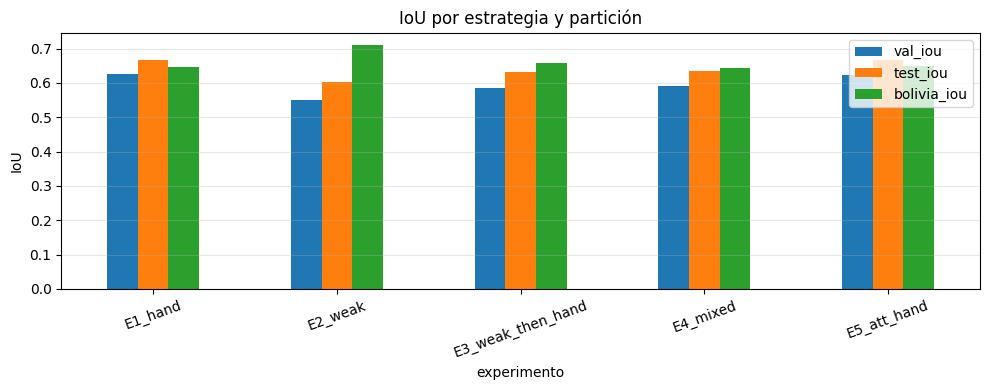

In [ ]:
tab = pd.DataFrame(results).T
tab.index.name = 'experimento'
tab = tab.drop(columns=['strategy', 'attention'], errors='ignore').astype(float).round(4)
tab = tab.reset_index()
tab.to_csv(f'{RES}/results.csv', index=False)
json.dump(results, open(f'{RES}/results.json', 'w'), indent=1)
cols = ['experimento', 'val_iou', 'test_iou', 'test_iou_chip', 'test_omission', 'test_commission',
        'bolivia_iou', 'bolivia_iou_chip', 'bolivia_omission', 'bolivia_commission']
display(tab[cols])
ax = tab.set_index('experimento')[['val_iou', 'test_iou', 'bolivia_iou']].plot.bar(figsize=(10, 4), rot=20)
ax.set_ylabel('IoU'); ax.set_title('IoU por estrategia y partición'); ax.grid(axis='y', alpha=.3)
plt.tight_layout(); plt.show()

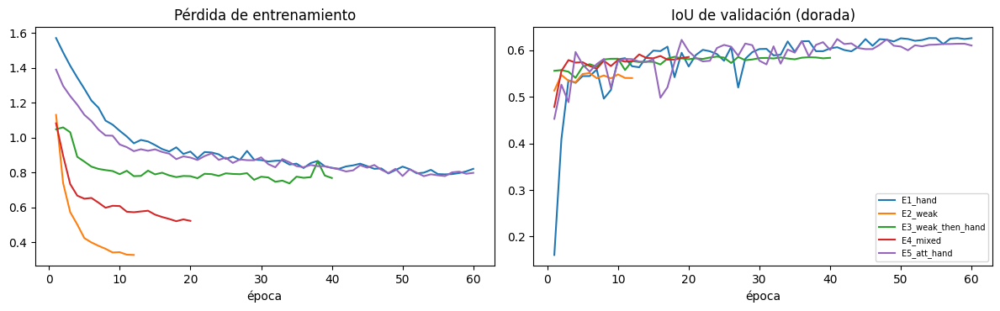

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for n, h in hists.items():
    if h:
        ax[0].plot([e['epoch'] for e in h], [e['loss'] for e in h], label=n)
        ax[1].plot([e['epoch'] for e in h], [e['val_iou'] for e in h], label=n)
ax[0].set_title('Pérdida de entrenamiento'); ax[1].set_title('IoU de validación (dorada)')
ax[0].set_xlabel('época'); ax[1].set_xlabel('época'); ax[1].legend(fontsize=7); plt.tight_layout(); plt.show()

## Generalización geográfica: IoU por evento en *test* y en Bolivia (modelo ganador)
La mejor configuración se elige por **validación**; aquí solo se reporta su desempeño por país.

In [ ]:
best_name = tab.sort_values('val_iou').iloc[-1]['experimento']
print('Modelo ganador (val IoU):', best_name)
att = results[best_name]['attention']
best_model = UNet(attention=att).to(device)
best_model.load_state_dict(torch.load(f'{CKPT}/{best_name}.pt', map_location=device))
open(f'{RES}/best_model.txt', 'w').write(f'{best_name},{att}')
rows = []
for split in ('test', 'bolivia'):
    for c in sorted({country(it['name']) for it in sp[split]}):
        its = [it for it in sp[split] if country(it['name']) == c]
        m = evaluate(best_model, make_loader(its), device)
        rows.append(dict(particion=split, evento=c, chips=m['n_chips'], iou=m['iou'], omision=m['omission'], comision=m['commission']))
display(pd.DataFrame(rows).round(3))

Modelo ganador (val IoU): E1_hand


,particion,evento,chips,iou,omision,comision
0,test,Ghana,11.0,0.541,0.417,0.117
1,test,India,14.0,0.718,0.182,0.145
2,test,Mekong,6.0,0.849,0.084,0.080
3,test,Nigeria,4.0,0.883,0.051,0.073
4,test,Pakistan,6.0,0.217,0.663,0.621
5,test,Paraguay,14.0,0.612,0.150,0.313
6,test,Somalia,6.0,0.517,0.422,0.170
7,test,Spain,6.0,0.728,0.127,0.185
8,test,Sri-Lanka,9.0,0.843,0.080,0.091
9,test,USA,14.0,0.565,0.172,0.360


## Resultados cualitativos en Bolivia (evento nunca visto)
Verde = acierto (TP) · Rojo = comisión (FP) · Azul = omisión (FN)

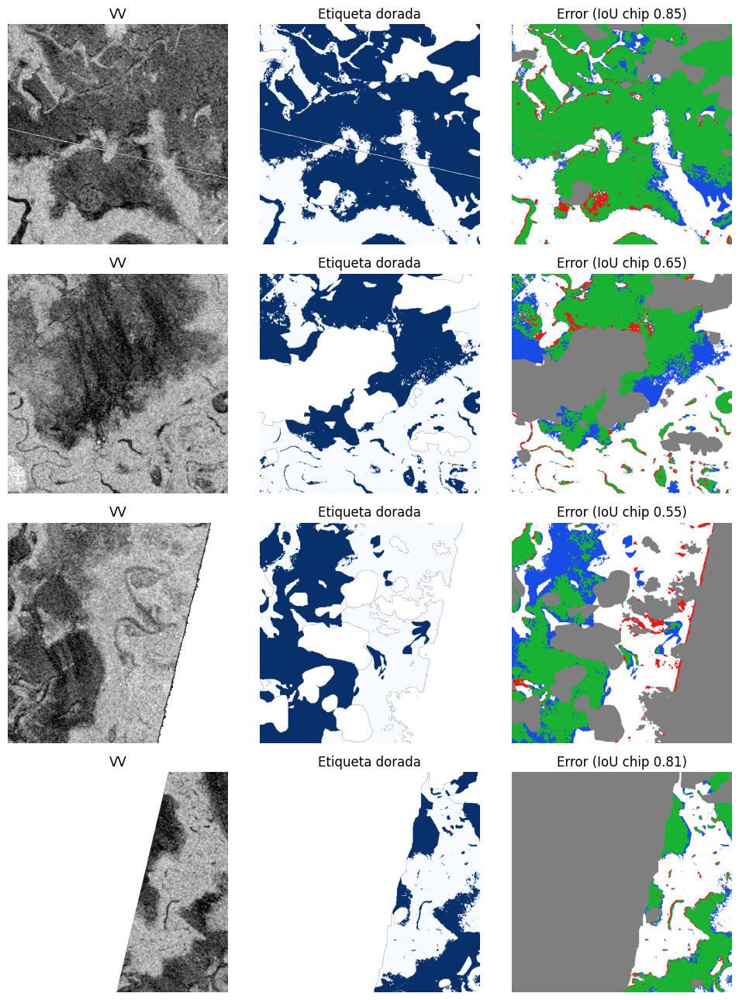

In [ ]:
P, Y, V = predict(best_model, bol_loader, device)
order = np.argsort(-(Y * V).sum((1, 2)).astype(np.int64))[:4]
fig, ax = plt.subplots(4, 3, figsize=(10, 13))
for r, i in enumerate(order):
    with rasterio.open(sp['bolivia'][i]['s1']) as d:
        vv = d.read(1)
    pred, y, v = P[i] > 0.5, Y[i].astype(bool), V[i]
    err = np.ones(pred.shape + (3,), np.float32)
    err[~y & ~pred] = 1; err[y & pred] = (0.1, 0.7, 0.2); err[~y & pred] = (0.9, 0.1, 0.1); err[y & ~pred] = (0.1, 0.3, 0.9); err[~v] = 0.5
    ax[r, 0].imshow(vv, cmap='gray', vmin=-25, vmax=0); ax[r, 0].set_title('VV')
    ax[r, 1].imshow(np.ma.masked_where(~v, y), cmap='Blues', vmin=0, vmax=1); ax[r, 1].set_title('Etiqueta dorada')
    ax[r, 2].imshow(err); ax[r, 2].set_title(f'Error (IoU chip {((pred & y & v).sum() / max(1, ((pred | y) & v).sum())):.2f})')
for a in ax.ravel(): a.axis('off')
plt.tight_layout(); plt.show()

---
# ENTREGABLE 2 · Estudio de ablación

Esta sección **no reentrena nada que ya exista**: reutiliza `results` / `results.json` de E1–E5 y añade, de forma opcional (banderas `RUN_*`), las ablaciones que faltaban.

,experimento,decision,val_IoU,test_IoU,test_F1,test_prec,test_rec,bolivia_IoU,d_val_IoU,d_test_IoU,d_bolivia_IoU
0,E1_hand,referencia,0.6262,0.6671,0.8003,0.8044,0.7962,0.6475,0.0000,0.0000,0.0000
1,E2_weak,(a) fuente,0.5511,0.6019,0.7515,0.7588,0.7444,0.7101,-0.0751,-0.0651,0.0627
2,E3_weak_then_hand,(a) fuente,0.5864,0.6330,0.7753,0.8016,0.7506,0.6591,-0.0398,-0.0340,0.0117
3,E4_mixed,(a) fuente,0.5910,0.6348,0.7766,0.8110,0.7450,0.6436,-0.0352,-0.0323,-0.0039
4,E5_att_hand,(b) conexiones de salto,0.6240,0.6667,0.8000,0.8141,0.7864,0.6491,-0.0022,-0.0004,0.0016


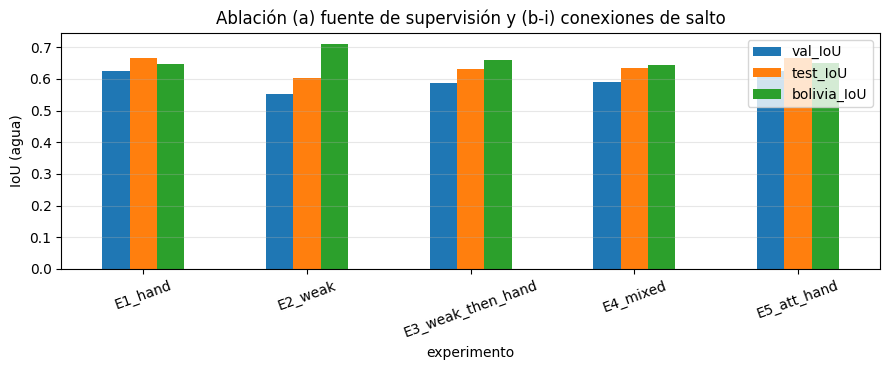

Lectura: d_* = IoU del experimento menos IoU de E1_hand (negativo = peor que solo dorada).


In [ ]:
# ===== Tabla de ablación (a) fuente de supervisión y (b-i) conexiones de salto =====
import json, os
import numpy as np, pandas as pd, matplotlib.pyplot as plt

if 'results' not in globals() or not results:
    results = json.load(open(f'{RES}/results.json'))          # si se reinició el runtime

ABL_DESC = {
    'E1_hand':           ('referencia', 'Solo dorada (252 chips de train)'),
    'E2_weak':           ('(a) fuente', 'Solo débil (Otsu)'),
    'E3_weak_then_hand': ('(a) fuente', 'Débil -> dorada (pre-entreno + fine-tuning)'),
    'E4_mixed':          ('(a) fuente', 'Mixta dorada+débil (50/50, peso débil WEAK_W)'),
    'E5_att_hand':       ('(b) conexiones de salto', 'Attention U-Net, solo dorada'),
}
rows = []
for k, (dec, desc) in ABL_DESC.items():
    if k not in results:
        continue
    r = results[k]; row = dict(experimento=k, decision=dec, descripcion=desc)
    for s in ('val', 'test', 'bolivia'):
        iou, om, co = r[f'{s}_iou'], r[f'{s}_omission'], r[f'{s}_commission']
        row[f'{s}_IoU']  = iou
        row[f'{s}_F1']   = r.get(f'{s}_f1', 2 * iou / (1 + iou))   # F1 = 2*IoU/(1+IoU) para IoU global
        row[f'{s}_prec'] = 1 - co                                   # precision = 1 - comision
        row[f'{s}_rec']  = 1 - om                                   # recall    = 1 - omision
    rows.append(row)
abl = pd.DataFrame(rows)
for s in ('val', 'test', 'bolivia'):
    abl[f'd_{s}_IoU'] = abl[f'{s}_IoU'] - abl.loc[abl.experimento == 'E1_hand', f'{s}_IoU'].iloc[0]
abl.to_csv(f'{RES}/ablacion_fuente_y_skip.csv', index=False)
display(abl[['experimento', 'decision', 'val_IoU', 'test_IoU', 'test_F1', 'test_prec', 'test_rec',
             'bolivia_IoU', 'd_val_IoU', 'd_test_IoU', 'd_bolivia_IoU']].round(4))

ax = abl.set_index('experimento')[['val_IoU', 'test_IoU', 'bolivia_IoU']].plot.bar(figsize=(9, 3.8), rot=20)
ax.set_ylabel('IoU (agua)'); ax.set_title('Ablación (a) fuente de supervisión y (b-i) conexiones de salto')
ax.grid(axis='y', alpha=.3); plt.tight_layout(); plt.show()
print('Lectura: d_* = IoU del experimento menos IoU de E1_hand (negativo = peor que solo dorada).')

### Ablación con varias semillas: función de pérdida, profundidad y fuente de supervisión

In [ ]:
# ===== Parámetros de la ablación con semillas =====
RUN_LOSS_ABL  = True     # (b-ii) BCE vs Dice vs BCE+Dice
RUN_DEPTH_ABL = False    # (b-iii) profundidad 3 / 4 / 5 (pérdida BCE+Dice)
RUN_SRC_ABL   = False    # (a) con semillas: solo dorada vs mixta
SEEDS   = [0, 1, 2]
LOSSES  = ['bce', 'dice', 'bce+dice']
DEPTHS  = [3, 4, 5]
EP_ABL  = EP_HAND        # mismas épocas que E1 para igualar el presupuesto

import torch, torch.nn.functional as F
ORIG_LOSS = globals().get('ORIG_LOSS', fu.masked_loss)      # pérdida original (BCE+Dice) de flood_utils

def make_loss(kind):
    """Misma máscara de píxeles válidos y pesos por muestra que flood_utils.masked_loss."""
    def loss_fn(logits, y, valid, w=None):
        bce = F.binary_cross_entropy_with_logits(logits, y, reduction='none')
        bce = (bce * valid).sum((1, 2, 3)) / valid.sum((1, 2, 3)).clamp(min=1)
        p = torch.sigmoid(logits) * valid; yy = y * valid
        inter = (p * yy).sum((1, 2, 3))
        dice = 1 - (2 * inter + 1) / (p.sum((1, 2, 3)) + yy.sum((1, 2, 3)) + 1)
        l = {'bce': bce, 'dice': dice, 'bce+dice': bce + dice}[kind]
        return (l * w).mean() if w is not None else l.mean()
    return loss_fn

def run_variant(strategy='hand', loss='bce+dice', depth=4, attention=False, seed=0):
    tag = f'{strategy}_{loss}_d{depth}_a{int(attention)}_s{seed}'
    ckpt, hist_f = f'{CKPT}/ABL_{tag}.pt', f'{RES}/hist_ABL_{tag}.json'
    set_seed(seed)
    model = UNet(depth=depth, attention=attention).to(device)
    if os.path.exists(ckpt) and os.path.exists(hist_f) and not RETRAIN:
        model.load_state_dict(torch.load(ckpt, map_location=device))
        return model, tag
    fu.masked_loss = make_loss(loss)                 # train_model usa masked_loss del módulo fu
    try:
        if strategy == 'hand':
            ds = FloodDataset(sp['train'], crop=CROP, augment=True)
            hist, _ = train_model(model, ds, val_loader, device, EP_ABL, 1e-3, ckpt=ckpt, verbose=False)
        elif strategy == 'mixed':
            ensure_weak()
            items = sp['train'] + [dict(it, w=WEAK_W) for it in weak]
            ds = FloodDataset(items, crop=CROP, augment=True)
            hist, _ = train_model(model, ds, val_loader, device, EP_MIX, 1e-3,
                                  sampler=make_sampler(items, 0.5, MIX_N), ckpt=ckpt, verbose=False)
        else:
            raise ValueError(strategy)
    finally:
        fu.masked_loss = ORIG_LOSS                   # siempre restaurar
    json.dump(hist, open(hist_f, 'w'))
    return model, tag

RUNS_F = f'{RES}/ablation_runs.json'
runs = json.load(open(RUNS_F)) if os.path.exists(RUNS_F) else {}

plan = []                                            # (grupo, factor, kwargs)
if RUN_LOSS_ABL:
    plan += [(f'loss={l}', 'perdida', dict(strategy='hand', loss=l, depth=4)) for l in LOSSES]
if RUN_DEPTH_ABL:
    plan += [(f'depth={d}', 'profundidad', dict(strategy='hand', loss='bce+dice', depth=d)) for d in DEPTHS]
if RUN_SRC_ABL:
    plan += [('fuente=dorada', 'fuente', dict(strategy='hand', loss='bce+dice', depth=4)),
             ('fuente=mixta', 'fuente', dict(strategy='mixed', loss='bce+dice', depth=4))]

for grupo, factor, kw in plan:
    for seed in SEEDS:
        key = f'{grupo}|s{seed}'
        if key in runs:
            continue
        model, tag = run_variant(seed=seed, **kw)
        m = evaluate_all(model)
        runs[key] = dict(grupo=grupo, factor=factor, seed=seed, tag=tag, **m)
        json.dump(runs, open(RUNS_F, 'w'), indent=1)
        print(f"{key:28s} val IoU {m['val_iou']:.4f} | test IoU {m['test_iou']:.4f} "
              f"| test F1 {m['test_f1']:.4f} | bolivia IoU {m['bolivia_iou']:.4f}")

val_iou         test_iou         test_f1          \
                         mean     std     mean     std    mean     std   
factor  grupo                                                            
perdida loss=bce       0.6229  0.0006   0.6548  0.0072  0.7914  0.0053   
        loss=bce+dice  0.6287  0.0101   0.6589  0.0027  0.7944  0.0019   
        loss=dice      0.6053  0.0052   0.6282  0.0114  0.7716  0.0087   

                      test_omission         test_commission          \
                               mean     std            mean     std   
factor  grupo                                                         
perdida loss=bce             0.2462  0.0182          0.1660  0.0309   
        loss=bce+dice        0.2079  0.0157          0.2029  0.0151   
        loss=dice            0.2019  0.0365          0.2504  0.0463   

                      bolivia_iou         n_semillas  
                             mean     std             
factor  grupo                                         
perdida loss=bce           0.6084  0.0587          3  
        loss=bce+dice      0.6444  0.0543          3  
        loss=dice          0.6407  0.0448          3

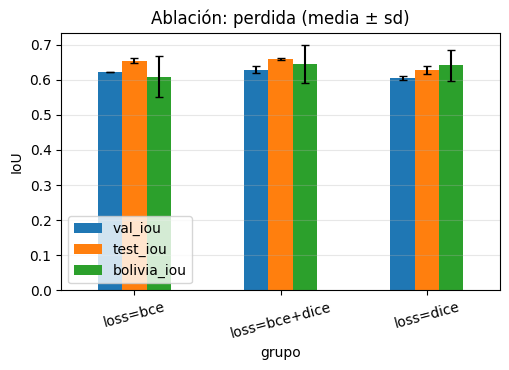

Criterio: una diferencia solo es creíble si supera claramente la desviación entre semillas.


In [ ]:
# ===== Resumen de la ablación con semillas: media ± desviación =====
runs = json.load(open(RUNS_F)) if os.path.exists(RUNS_F) else {}
if not runs:
    print('Aún no hay corridas: activa RUN_LOSS_ABL / RUN_DEPTH_ABL / RUN_SRC_ABL y ejecuta la celda anterior.')
else:
    df = pd.DataFrame(runs).T
    num = ['val_iou', 'test_iou', 'test_f1', 'test_omission', 'test_commission', 'bolivia_iou']
    df[num] = df[num].astype(float)
    # E1 original (seed 42, BCE+Dice, depth 4) como fila de contexto
    summ = df.groupby(['factor', 'grupo'])[num].agg(['mean', 'std']).round(4)
    summ['n_semillas'] = df.groupby(['factor', 'grupo']).size()
    display(summ)
    summ.to_csv(f'{RES}/ablacion_semillas_resumen.csv')
    df.to_csv(f'{RES}/ablacion_semillas_corridas.csv', index=False)
    fig, axes = plt.subplots(1, df.factor.nunique(), figsize=(5.2 * df.factor.nunique(), 3.8), squeeze=False)
    for ax, (fac, d) in zip(axes[0], df.groupby('factor')):
        g = d.groupby('grupo')[['val_iou', 'test_iou', 'bolivia_iou']]
        mu, sd = g.mean(), g.std().fillna(0)
        mu.plot.bar(yerr=sd, ax=ax, rot=15, capsize=3)
        ax.set_title(f'Ablación: {fac} (media ± sd)'); ax.set_ylabel('IoU'); ax.grid(axis='y', alpha=.3)
    plt.tight_layout(); plt.show()
    print('Criterio: una diferencia solo es creíble si supera claramente la desviación entre semillas.')

---
# ENTREGABLE 3 · Evaluación en distribución (chips dorados de eventos vistos)

In [ ]:
# ===== Funciones auxiliares (solo numpy) =====
def per_chip_counts(P, Y, V, thr=0.5):
    """Devuelve array (N,4) con [TP, FP, FN, TN] por chip, solo píxeles válidos."""
    pred = P.astype(np.float32) > thr; y = Y.astype(bool); v = V.astype(bool)
    tp = (pred & y & v).sum((1, 2)); fp = (pred & ~y & v).sum((1, 2))
    fn = (~pred & y & v).sum((1, 2)); tn = (~pred & ~y & v).sum((1, 2))
    return np.stack([tp, fp, fn, tn], 1).astype(np.int64)

def metrics_from_counts(c):
    tp, fp, fn, tn = [float(x) for x in c]; e = 1e-12
    return dict(iou=tp / (tp + fp + fn + e), f1=2 * tp / (2 * tp + fp + fn + e),
                precision=tp / (tp + fp + e), recall=tp / (tp + fn + e),
                omission=fn / (tp + fn + e), commission=fp / (tp + fp + e),
                accuracy=(tp + tn) / (tp + fp + fn + tn + e))

def bootstrap_ci(C, B=1000, seed=0):
    """IC 95 % percentil remuestreando CHIPS con reemplazo (C: (N,4) conteos por chip)."""
    rng = np.random.default_rng(seed); n = len(C); keys = None; out = []
    for _ in range(B):
        m = metrics_from_counts(C[rng.integers(0, n, n)].sum(0))
        keys = keys or list(m); out.append([m[k] for k in keys])
    lo, hi = np.percentile(np.array(out), [2.5, 97.5], axis=0)
    return {k: (l, h) for k, l, h in zip(keys, lo, hi)}

def comment_confusion(name, c, thr=0.5):
    """Imprime una lectura automática de la matriz de confusión (c = [TP, FP, FN, TN])."""
    tp, fp, fn, tn = [int(x) for x in c]; N = tp + fp + fn + tn; m = metrics_from_counts(c)
    prev = (tp + fn) / N; base_acc = 1 - prev
    spec = tn / (tn + fp); npv = tn / (tn + fn)
    ratio = fp / max(fn, 1)
    sesgo = ('SOBREDETECTA agua (más falsos positivos que omisiones)' if ratio > 1.15 else
             'SUBDETECTA agua (más omisiones que falsos positivos)' if ratio < 1 / 1.15 else
             'tiene errores EQUILIBRADOS (FP ≈ FN)')
    print(f'=== Lectura de la matriz de confusión · {name} · umbral {thr} ===')
    print(f'1) Composición: {N:,} píxeles válidos; agua real = {prev:.2%}. Un clasificador que dijera "no agua" '
          f'siempre tendría exactitud {base_acc:.2%} (IoU = 0): la exactitud global ({m["accuracy"]:.2%}) NO sirve aquí.')
    print(f'2) Recall = {m["recall"]:.3f}: de cada 100 píxeles de agua real, {m["omission"]*100:.1f} se omiten '
          f'(FN = {fn:,}).')
    print(f'3) Precisión = {m["precision"]:.3f}: de cada 100 píxeles predichos como agua, {m["commission"]*100:.1f} '
          f'son falsos (FP = {fp:,}).')
    print(f'4) Especificidad = {spec:.3f} y valor predictivo negativo = {npv:.3f}: ' +
          ('la clase "no agua" casi no es el problema; el error está en la clase agua.' if spec > 0.95 else
           'la clase "no agua" también se confunde con frecuencia (revisar FP).'))
    print(f'5) FP/FN = {ratio:.2f} -> el modelo {sesgo}.')
    print(f'6) IoU = {m["iou"]:.3f} y F1 = {m["f1"]:.3f}: el error (FP+FN) equivale a {(fp+fn)/(tp+fp+fn):.1%} del área unión '
          f'predicción ∪ referencia.')
    print('7) Interpretar con cautela: test es EN distribución (mismos eventos que train) -> estimación optimista '
          'del rendimiento en un evento nuevo.')

# --- prueba rápida con datos sintéticos (no necesita GPU) ---
_rng = np.random.default_rng(0)
_Y = (_rng.random((6, 64, 64)) < .1).astype(np.uint8); _P = np.where(_rng.random((6, 64, 64)) < .85, _Y, 1 - _Y).astype(np.float16)
_C = per_chip_counts(_P, _Y, np.ones_like(_Y, bool))
assert _C.sum() == _Y.size and abs(metrics_from_counts(_C.sum(0))['f1'] - 2 * metrics_from_counts(_C.sum(0))['iou'] / (1 + metrics_from_counts(_C.sum(0))['iou'])) < 1e-9
print('Funciones auxiliares OK')

Funciones auxiliares OK


In [ ]:
# ===== Verificación: test es EN distribución (eventos de test ⊂ eventos de train) =====
ev_train = {country(it['name']) for it in sp['train']}
ev_test  = {country(it['name']) for it in sp['test']}
ev_bol   = {country(it['name']) for it in sp['bolivia']}
print('Eventos en train :', sorted(ev_train))
print('Eventos en test  :', sorted(ev_test), '-> todos vistos en train:', ev_test <= ev_train)
print('Eventos en Bolivia:', sorted(ev_bol), '-> ausentes de train:', not (ev_bol & ev_train))
assert ev_test <= ev_train, 'test contiene eventos no vistos: no es evaluación en distribución'

# ===== Evaluación en distribución de TODOS los modelos (test) con conteos exactos e IC bootstrap =====
names = [k for k in results if k.startswith('E') and os.path.exists(f'{CKPT}/{k}.pt')]
best_name = max(names, key=lambda k: results[k]['val_iou'])         # elegido por VALIDACIÓN (sin fuga)
print('Modelo elegido por validación:', best_name)

PRED = {}                                    # cache de predicciones por modelo y partición
def get_pred(name, split):
    if (name, split) not in PRED:
        m = UNet(attention=bool(results[name].get('attention', False))).to(device)
        m.load_state_dict(torch.load(f'{CKPT}/{name}.pt', map_location=device))
        PRED[(name, split)] = predict(m, make_loader(sp[split]), device)
        del m
    return PRED[(name, split)]

rows, CCHIP = [], {}
for n in names:
    P, Y, V = get_pred(n, 'test')
    C = per_chip_counts(P, Y, V); CCHIP[n] = C
    tot = C.sum(0); m = metrics_from_counts(tot); ci = bootstrap_ci(C)
    rows.append(dict(modelo=n, TP=tot[0], FP=tot[1], FN=tot[2], TN=tot[3],
                     IoU=m['iou'], F1=m['f1'], Precision=m['precision'], Recall=m['recall'],
                     Omision=m['omission'], Comision=m['commission'], Exactitud=m['accuracy'],
                     **{f'{k}_IC95': f'[{ci[k][0]:.3f}, {ci[k][1]:.3f}]' for k in ('iou', 'f1', 'precision', 'recall')}))
indist = pd.DataFrame(rows)
indist.to_csv(f'{RES}/evaluacion_en_distribucion_test.csv', index=False)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 30)
display(indist[['modelo', 'IoU', 'F1', 'Precision', 'Recall', 'Omision', 'Comision', 'Exactitud']].round(4))
display(indist[['modelo', 'TP', 'FP', 'FN', 'TN', 'iou_IC95', 'f1_IC95', 'precision_IC95', 'recall_IC95']])
print('IC95 %: bootstrap de 1000 remuestreos de chips (los chips de un mismo evento no son independientes: el IC es optimista).')

# Contraste con el IoU reportado por evaluate_all (debe coincidir)
for n in names:
    assert abs(indist.set_index('modelo').loc[n, 'IoU'] - results[n]['test_iou']) < 2e-3, f'IoU distinto en {n}'
print('Verificación: IoU recalculado == IoU de evaluate_all (±0.002) para todos los modelos.')

Eventos en train : ['Ghana', 'India', 'Mekong', 'Nigeria', 'Pakistan', 'Paraguay', 'Somalia', 'Spain', 'Sri-Lanka', 'USA']
Eventos en test  : ['Ghana', 'India', 'Mekong', 'Nigeria', 'Pakistan', 'Paraguay', 'Somalia', 'Spain', 'Sri-Lanka', 'USA'] -> todos vistos en train: True
Eventos en Bolivia: ['Bolivia'] -> ausentes de train: True
Modelo elegido por validación: E1_hand


,modelo,IoU,F1,Precision,Recall,Omision,Comision,Exactitud
0,E1_hand,0.6671,0.8003,0.8044,0.7962,0.2038,0.1956,0.9511
1,E2_weak,0.6019,0.7515,0.7588,0.7444,0.2556,0.2412,0.9394
2,E3_weak_then_hand,0.6330,0.7753,0.8016,0.7506,0.2494,0.1984,0.9465
3,E4_mixed,0.6348,0.7766,0.8110,0.7450,0.2550,0.1890,0.9473
4,E5_att_hand,0.6667,0.8000,0.8141,0.7864,0.2136,0.1859,0.9516


,modelo,TP,FP,FN,TN,iou_IC95,f1_IC95,precision_IC95,recall_IC95
0,E1_hand,2002365,486763,512643,17442188,"[0.553, 0.752]","[0.712, 0.859]","[0.709, 0.861]","[0.679, 0.876]"
1,E2_weak,1872076,595039,642932,17333912,"[0.480, 0.697]","[0.649, 0.822]","[0.633, 0.846]","[0.622, 0.831]"
2,E3_weak_then_hand,1887869,467260,627139,17461691,"[0.508, 0.728]","[0.674, 0.842]","[0.697, 0.869]","[0.620, 0.843]"
3,E4_mixed,1873667,436535,641341,17492416,"[0.511, 0.729]","[0.676, 0.844]","[0.707, 0.877]","[0.614, 0.838]"
4,E5_att_hand,1977678,451546,537330,17477405,"[0.552, 0.752]","[0.711, 0.859]","[0.721, 0.870]","[0.664, 0.868]"


IC95 %: bootstrap de 1000 remuestreos de chips (los chips de un mismo evento no son independientes: el IC es optimista).
Verificación: IoU recalculado == IoU de evaluate_all (±0.002) para todos los modelos.


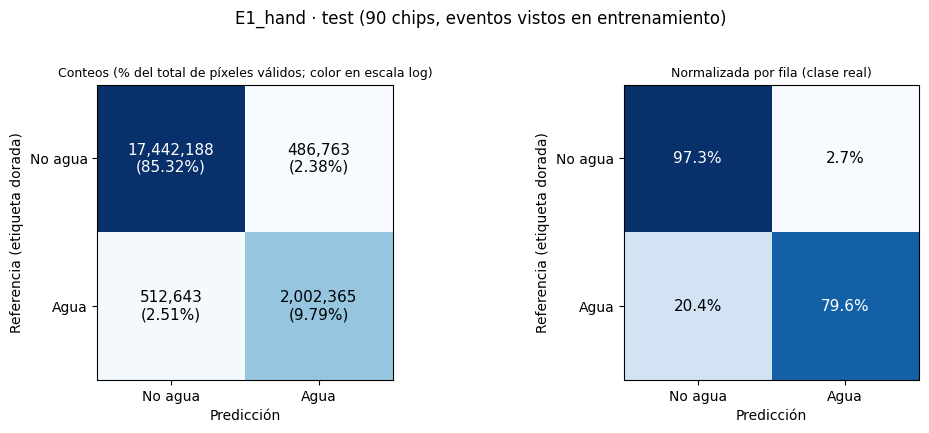

,evento,chips,IoU,F1,Precision,Recall,Omision,Comision
3,Nigeria,4,0.883,0.938,0.927,0.949,0.051,0.073
2,Mekong,6,0.849,0.918,0.920,0.916,0.084,0.080
8,Sri-Lanka,9,0.843,0.915,0.909,0.920,0.080,0.091
7,Spain,6,0.728,0.843,0.815,0.873,0.127,0.185
1,India,14,0.718,0.836,0.855,0.818,0.182,0.145
5,Paraguay,14,0.612,0.760,0.687,0.850,0.150,0.313
9,USA,14,0.565,0.722,0.640,0.828,0.172,0.360
0,Ghana,11,0.541,0.702,0.883,0.583,0.417,0.117
6,Somalia,6,0.517,0.681,0.830,0.578,0.422,0.170
4,Pakistan,6,0.217,0.357,0.379,0.337,0.663,0.621


In [ ]:
# ===== Matriz de confusión del modelo elegido (test, en distribución) =====
P, Y, V = get_pred(best_name, 'test')
C = per_chip_counts(P, Y, V); tp, fp, fn, tn = C.sum(0)
M = np.array([[tn, fp], [fn, tp]], dtype=float)                    # filas = referencia, columnas = predicción
lab = ['No agua', 'Agua']
frac, rown = M / M.sum(), M / M.sum(1, keepdims=True)
panels = [(np.log10(frac + 1e-6), 'Conteos (% del total de píxeles válidos; color en escala log)',
           lambda i, j: f'{int(M[i, j]):,}\n({frac[i, j]:.2%})'),
          (rown, 'Normalizada por fila (clase real)', lambda i, j: f'{rown[i, j]:.1%}')]
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for a, (img, title, fmt) in zip(ax, panels):
    a.imshow(img, cmap='Blues')
    cut = img.min() + 0.55 * (img.max() - img.min())
    for i in range(2):
        for j in range(2):
            a.text(j, i, fmt(i, j), ha='center', va='center', fontsize=11, color='white' if img[i, j] > cut else 'black')
    a.set_xticks([0, 1]); a.set_yticks([0, 1]); a.set_xticklabels(lab); a.set_yticklabels(lab)
    a.set_xlabel('Predicción'); a.set_ylabel('Referencia (etiqueta dorada)'); a.set_title(title, fontsize=9)
plt.suptitle(f'{best_name} · test (90 chips, eventos vistos en entrenamiento)', y=1.02)
plt.tight_layout(); plt.savefig(f'{RES}/matriz_confusion_{best_name}_test.png', dpi=200, bbox_inches='tight'); plt.show()

# ===== Detalle por evento (mismo modelo): precisión, recall, F1 =====
ev = np.array([country(it['name']) for it in sp['test']])
rows = []
for e in sorted(set(ev)):
    m = metrics_from_counts(C[ev == e].sum(0))
    rows.append(dict(evento=e, chips=int((ev == e).sum()), IoU=m['iou'], F1=m['f1'], Precision=m['precision'],
                     Recall=m['recall'], Omision=m['omission'], Comision=m['commission']))
by_event = pd.DataFrame(rows).sort_values('IoU', ascending=False)
by_event.to_csv(f'{RES}/en_distribucion_por_evento_{best_name}.csv', index=False)
display(by_event.round(3))

In [ ]:
# ===== Matriz de confusión COMENTADA (texto generado a partir de los conteos exactos) =====
comment_confusion(best_name, C.sum(0))
print()
# Qué eventos concentran los errores (para el comentario del informe)
tot_fp, tot_fn = C[:, 1].sum(), C[:, 2].sum()
share = pd.DataFrame({'evento': ev, 'FP': C[:, 1], 'FN': C[:, 2]}).groupby('evento').sum()
share['%FP_total'] = share.FP / tot_fp * 100; share['%FN_total'] = share.FN / tot_fn * 100
display(share.sort_values('%FP_total', ascending=False).round(1))
print('Lee la tabla: los eventos con mayor %FP concentran la sobredetección; los de mayor %FN, las omisiones.')

=== Lectura de la matriz de confusión · E1_hand · umbral 0.5 ===
1) Composición: 20,443,959 píxeles válidos; agua real = 12.30%. Un clasificador que dijera "no agua" siempre tendría exactitud 87.70% (IoU = 0): la exactitud global (95.11%) NO sirve aquí.
2) Recall = 0.796: de cada 100 píxeles de agua real, 20.4 se omiten (FN = 512,643).
3) Precisión = 0.804: de cada 100 píxeles predichos como agua, 19.6 son falsos (FP = 486,763).
4) Especificidad = 0.973 y valor predictivo negativo = 0.971: la clase "no agua" casi no es el problema; el error está en la clase agua.
5) FP/FN = 0.95 -> el modelo tiene errores EQUILIBRADOS (FP ≈ FN).
6) IoU = 0.667 y F1 = 0.800: el error (FP+FN) equivale a 33.3% del área unión predicción ∪ referencia.
7) Interpretar con cautela: test es EN distribución (mismos eventos que train) -> estimación optimista del rendimiento en un evento nuevo.



,FP,FN,%FP_total,%FN_total
evento,,,,
Pakistan,109596,131944,22.5,25.7
India,94978,125279,19.5,24.4
Paraguay,74124,28664,15.2,5.6
Spain,70042,44690,14.4,8.7
USA,53827,19841,11.1,3.9
Sri-Lanka,35014,30244,7.2,5.9
Mekong,16650,17718,3.4,3.5
Ghana,13198,71442,2.7,13.9
Somalia,10219,36605,2.1,7.1


Lee la tabla: los eventos con mayor %FP concentran la sobredetección; los de mayor %FN, las omisiones.


---
# ENTREGABLES 5 y 6 · Fallos característicos SAR y fusión SAR + óptico (Sentinel-2)

Esta sección **no reentrena nada de E1–E5**: reutiliza `best_name`, `get_pred`, `results`, `sp` y las funciones de secciones anteriores
Las funciones auxiliares se guardan en `flood_diag.py` (Drive), que también importa el notebook 03.

In [ ]:
%%writefile /content/drive/MyDrive/Dagua/code/flood_diag.py
"""Diagnóstico y fusión SAR+óptico para Sen1Floods11 / Lima.
Escrito por el notebook 02 (sección ENTREGABLES 5-6); lo importa también el notebook 03."""
import os, random, math
import numpy as np
import rasterio
from rasterio.vrt import WarpedVRT
from rasterio.enums import Resampling
from scipy import ndimage as ndi

try:
    import torch
    from torch.utils.data import Dataset
except Exception:                      # permite importar el módulo sin torch (solo para pruebas)
    torch, Dataset = None, object

S2_NAMES = ['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B9', 'B10', 'B11', 'B12']
S2_IDX = {n: i for i, n in enumerate(S2_NAMES)}
GCS_HTTP = 'https://storage.googleapis.com/sen1floods11/v1.1/data/flood_events/HandLabeled'


# ----------------------------------------------------------------------------- Sentinel-2
def s2_path(s1_path):
    """.../S1Hand/Bolivia_103757_S1Hand.tif -> .../S2Hand/Bolivia_103757_S2Hand.tif"""
    return s1_path.replace('S1Hand', 'S2Hand')


def fetch_s2hand(items, local, workers=16, retries=3):
    """Descarga por HTTPS (en paralelo e incremental) solo los S2Hand de los chips dados."""
    import requests
    from concurrent.futures import ThreadPoolExecutor
    os.makedirs(f'{local}/HandLabeled/S2Hand', exist_ok=True)
    jobs = []
    for it in items:
        fn = os.path.basename(s2_path(it['s1']))
        dst = f'{local}/HandLabeled/S2Hand/{fn}'
        if not (os.path.exists(dst) and os.path.getsize(dst) > 0):
            jobs.append((f'{GCS_HTTP}/S2Hand/{fn}', dst))
    print(f'S2Hand por descargar: {len(jobs)} de {len(items)}')
    sess = requests.Session()

    def _get(a):
        url, dst = a
        err = None
        for _ in range(retries):
            try:
                with sess.get(url, stream=True, timeout=120) as r:
                    r.raise_for_status()
                    with open(dst + '.part', 'wb') as f:
                        for ch in r.iter_content(1 << 20):
                            f.write(ch)
                os.replace(dst + '.part', dst)
                return None
            except Exception as e:
                err = repr(e)
        return f'{os.path.basename(dst)}: {err}'
    with ThreadPoolExecutor(workers) as ex:
        fails = [r for r in ex.map(_get, jobs) if r]
    if fails:
        print('[ERROR descarga S2Hand] ejemplos:', fails[:3])
    return len(jobs) - len(fails)


def read_s2(path):
    """(13,H,W) reflectancia TOA (0-1). Sen1Floods11 guarda reflectancia x 10000: se detecta la escala."""
    with rasterio.open(path) as d:
        x = d.read().astype(np.float32)
    x = np.nan_to_num(x, nan=0.0)
    if np.percentile(x[3], 99) > 2.0:
        x = x / 10000.0
    return x


def optical_indices(r):
    """Índices a partir de reflectancia (13,H,W): NDVI, MNDWI, brillo visible, blancura."""
    e = 1e-6
    b2, b3, b4, b8, b11 = r[S2_IDX['B2']], r[S2_IDX['B3']], r[S2_IDX['B4']], r[S2_IDX['B8']], r[S2_IDX['B11']]
    ndvi = (b8 - b4) / (b8 + b4 + e)
    mndwi = (b3 - b11) / (b3 + b11 + e)
    mx, mn = np.maximum(np.maximum(b2, b3), b4), np.minimum(np.minimum(b2, b3), b4)
    return dict(ndvi=ndvi, mndwi=mndwi, bright=(b2 + b3 + b4) / 3, white=(mx - mn) / (mx + e), b11=b11)


def cloud_mask_s2(r, dil=3):
    """Máscara heurística de nubes/cirros sobre L1C (no hay SCL ni s2cloudless en Sen1Floods11).
    Nube gruesa: azul alto, espectro plano (blancura baja), no nieve; cirros: banda B10 alta. Se dilata `dil` px.
    Es una APROXIMACIÓN: revisar visualmente (celda de control) y ajustar umbrales si hace falta."""
    ix = optical_indices(r)
    b2, b3, b10 = r[S2_IDX['B2']], r[S2_IDX['B3']], r[S2_IDX['B10']]
    ndsi = (b3 - ix['b11']) / (b3 + ix['b11'] + 1e-6)
    thick = (b2 > 0.18) & (ix['bright'] > 0.20) & (ix['white'] < 0.35) & (ndsi < 0.6)
    cirrus = b10 > 0.012
    m = thick | cirrus | (r.max(0) == 0)          # el último término: píxel sin dato óptico
    return ndi.binary_dilation(m, iterations=dil) if dil else m


def cloud_fraction(s2_file, valid_only=None):
    r = read_s2(s2_file)
    m = cloud_mask_s2(r)
    return float(m.mean())


# ----------------------------------------------------------------------------- dataset SAR (+ óptico)
class FusionDataset(Dataset):
    """Igual que FloodDataset pero con canales S2 opcionales.
    mode='sar'    -> 2 canales (VV,VH)            [mismo recorte/aumento que 'fusion' si se fija la semilla]
    mode='fusion' -> 2 + len(bands) canales (S2 normalizado con mean/std de train).
    items: dict(s1, lab, w, src, name)."""
    def __init__(self, items, mode='fusion', bands=('B2', 'B3', 'B4', 'B8', 'B11', 'B12'),
                 mean=None, std=None, crop=None, augment=False):
        self.items, self.mode, self.bands = items, mode, list(bands)
        self.idx = [S2_IDX[b] for b in self.bands]
        self.mean = None if mean is None else np.asarray(mean, np.float32)[:, None, None]
        self.std = None if std is None else np.asarray(std, np.float32)[:, None, None]
        self.crop, self.augment = crop, augment

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        from flood_utils import normalize_s1
        it = self.items[i]
        with rasterio.open(it['s1']) as d:
            raw = d.read().astype(np.float32)
        x, bad = normalize_s1(raw)
        with rasterio.open(it['lab']) as d:
            lab = d.read(1).astype(np.int16)
        valid = (lab >= 0) & (~bad)
        y = (lab == 1).astype(np.float32)
        x = x * (~bad)[None]
        if self.mode == 'fusion':
            s2 = read_s2(s2_path(it['s1']))[self.idx]
            s2 = (s2 - self.mean) / self.std
            x = np.concatenate([x, s2.astype(np.float32)], 0)
        y, valid = y[None], valid.astype(np.float32)[None]
        if self.crop:
            H, W = y.shape[1:]
            r, c = random.randint(0, H - self.crop), random.randint(0, W - self.crop)
            x, y, valid = [a[:, r:r + self.crop, c:c + self.crop] for a in (x, y, valid)]
        if self.augment:
            k = random.randint(0, 3)
            x, y, valid = [np.rot90(a, k, axes=(1, 2)) for a in (x, y, valid)]
            if random.random() < 0.5:
                x, y, valid = [a[:, :, ::-1] for a in (x, y, valid)]
        x, y, valid = [torch.from_numpy(np.ascontiguousarray(a)) for a in (x, y, valid)]
        return x, y, valid, torch.tensor(float(it.get('w', 1.0))), i


def s2_stats(items, bands, max_chips=120, seed=0):
    """Media/desvío por banda sobre chips de train (píxeles con dato óptico)."""
    idx = [S2_IDX[b] for b in bands]
    rng = random.Random(seed)
    sel = items if len(items) <= max_chips else rng.sample(items, max_chips)
    s, s2_, n = np.zeros(len(idx)), np.zeros(len(idx)), 0
    for it in sel:
        r = read_s2(s2_path(it['s1']))[idx]
        ok = r.max(0) > 0
        v = r[:, ok]
        s += v.sum(1); s2_ += (v.astype(np.float64) ** 2).sum(1); n += v.shape[1]
    mean = s / n
    std = np.sqrt(np.maximum(s2_ / n - mean ** 2, 1e-12))
    return mean.astype(np.float32), std.astype(np.float32)


# ----------------------------------------------------------------------------- terreno (DEM Copernicus GLO-30, COG público en AWS)
def _tile_url(lat, lon):
    ns, ew = ('N' if lat >= 0 else 'S'), ('E' if lon >= 0 else 'W')
    n = f'Copernicus_DSM_COG_10_{ns}{abs(lat):02d}_00_{ew}{abs(lon):03d}_00_DEM'
    return f'https://copernicus-dem-30m.s3.amazonaws.com/{n}/{n}.tif'


def dem_slope(chip_path):
    """Pendiente (grados) en la grilla del chip, o None si no se pudo leer el DEM (sin red, tesela ausente...)."""
    try:
        with rasterio.open(chip_path) as ch:
            tr, crs, H, W, b = ch.transform, ch.crs, ch.height, ch.width, ch.bounds
        lats = {math.floor(b.bottom), math.floor(b.top)}
        lons = {math.floor(b.left), math.floor(b.right)}
        dem = np.full((H, W), np.nan, np.float32)
        for la in lats:
            for lo in lons:
                try:
                    with rasterio.open(_tile_url(la, lo)) as s, \
                         WarpedVRT(s, crs=crs, transform=tr, width=W, height=H, resampling=Resampling.bilinear) as v:
                        a = v.read(1).astype(np.float32)
                    dem = np.where(np.isnan(dem), a, dem)
                except Exception:
                    continue
        if np.isnan(dem).all():
            return None
        dem = np.where(np.isnan(dem), np.nanmedian(dem), dem)
        dem = ndi.gaussian_filter(dem, 1.0)
        lat0 = (b.top + b.bottom) / 2
        dy = abs(tr.e) * 111320.0
        dx = abs(tr.a) * 111320.0 * math.cos(math.radians(lat0))
        gy, gx = np.gradient(dem, dy, dx)
        return np.degrees(np.arctan(np.hypot(gx, gy))).astype(np.float32)
    except Exception:
        return None


# ----------------------------------------------------------------------------- minería y visualización de errores
def label_components(mask, min_px=150):
    """Elimina componentes conexas < min_px (para no clasificar ruido de 1-2 píxeles)."""
    lab, n = ndi.label(mask)
    if n == 0:
        return mask
    sz = ndi.sum(mask, lab, range(1, n + 1))
    keep = np.isin(lab, 1 + np.where(sz >= min_px)[0])
    return keep


def classify_errors(pred, y, v, vv, vh, ndvi=None, mndwi=None, slope=None, builtup=None,
                    slope_thr=8.0, vv_bright=-12.0, min_px=150):
    """Devuelve dict tipo -> máscara booleana (HxW). Tipos (mutuamente excluyentes, orden de prioridad):
      FP_sombra_terreno   : pred agua, no agua en ref., pendiente >= slope_thr (sombra de radar / vertiente de espaldas)
      FP_suelo_humedo     : pred agua, no agua en ref., terreno llano, óptico dice tierra (MNDWI<0) y poca vegetación
      FP_etiqueta_dudosa  : pred agua, no agua en ref., óptico dice AGUA (MNDWI>0.2) -> posible omisión de la etiqueta
      FN_doble_rebote_urb : agua en ref., no detectada, VV alto (> vv_bright) y urbano (builtup, o NDVI bajo si no hay capa)
      FN_doble_rebote_veg : agua en ref., no detectada, VV alto y vegetación (NDVI >= 0.3)
      FN_retorno_alto_otro: agua en ref., no detectada, VV alto sin más información
    Si falta una capa auxiliar (slope/ndvi/mndwi/builtup) los tipos que dependen de ella no se generan."""
    fp = pred & ~y & v
    fn = ~pred & y & v
    out, used = {}, np.zeros_like(fp)

    def add(name, m):
        m = label_components(m & ~used, min_px)
        if m.any():
            out[name] = m; used.__ior__(m)

    if slope is not None:
        add('FP_sombra_terreno', fp & (slope >= slope_thr))
    if mndwi is not None:
        flat = fp if slope is None else fp & (slope < slope_thr)
        veg = (ndvi < 0.3) if ndvi is not None else np.ones_like(fp)
        add('FP_suelo_humedo', flat & (mndwi < 0) & veg)
        add('FP_etiqueta_dudosa', fp & (mndwi > 0.2))
    bright = fn & (vv > vv_bright)
    if builtup is not None:
        add('FN_doble_rebote_urb', bright & builtup)
        if ndvi is not None:
            add('FN_doble_rebote_veg', bright & ~builtup & (ndvi >= 0.3))
    elif ndvi is not None:
        add('FN_doble_rebote_urb', bright & (ndvi < 0.3))
        add('FN_doble_rebote_veg', bright & (ndvi >= 0.3))
    add('FN_retorno_alto_otro', bright)
    return out


def crop_around(mask, size=192):
    """Ventana (r0,r1,c0,c1) de `size` px centrada en el centroide de la componente más grande de mask."""
    lab, n = ndi.label(mask)
    if n == 0:
        return 0, mask.shape[0], 0, mask.shape[1]
    sz = ndi.sum(mask, lab, range(1, n + 1))
    cy, cx = [int(round(t)) for t in ndi.center_of_mass(mask, lab, 1 + int(np.argmax(sz)))]
    H, W = mask.shape
    r0 = int(np.clip(cy - size // 2, 0, max(H - size, 0))); c0 = int(np.clip(cx - size // 2, 0, max(W - size, 0)))
    return r0, min(r0 + size, H), c0, min(c0 + size, W)


def rgb_stretch(r, lo=2, hi=98):
    """Composición color natural (B4,B3,B2) con estiramiento por percentiles."""
    rgb = np.stack([r[S2_IDX['B4']], r[S2_IDX['B3']], r[S2_IDX['B2']]], -1)
    a, b = np.percentile(rgb[rgb > 0], [lo, hi]) if (rgb > 0).any() else (0, 1)
    return np.clip((rgb - a) / max(b - a, 1e-6), 0, 1)

Writing /content/drive/MyDrive/Dagua/code/flood_diag.py


In [ ]:
# ===== Preparación: importar módulo y descargar S2Hand (solo los chips de los splits) =====
import importlib, sys
sys.path.insert(0, f'{BASE}/code')
import flood_diag as fd; importlib.reload(fd)
import json, random, numpy as np, pandas as pd, matplotlib.pyplot as plt, rasterio, os

_need = ['sp', 'device', 'CKPT', 'RES', 'results', 'best_name', 'get_pred', 'per_chip_counts',
         'metrics_from_counts', 'bootstrap_ci', 'CROP', 'EP_HAND', 'RETRAIN', 'LOCAL']
_miss = [n for n in _need if n not in globals()]
assert not _miss, f'Faltan {_miss}: ejecuta primero este notebook hasta el ENTREGABLE 3 (celda de matriz de confusión).'

ALL_ITEMS = [it for k in ('train', 'val', 'test', 'bolivia') for it in sp[k]]
fd.fetch_s2hand(ALL_ITEMS, LOCAL)
_no_s2 = [it['name'] for it in ALL_ITEMS if not os.path.exists(fd.s2_path(it['s1']))]
print('chips sin S2Hand:', len(_no_s2), _no_s2[:3])
assert len(_no_s2) == 0, 'Faltan S2Hand: revisa los [ERROR descarga S2Hand] y vuelve a ejecutar.'

# Chequeo de formato (bandas, escala): si la escala no fuera reflectancia 0-1 tras read_s2, ajustar fd.read_s2
with rasterio.open(fd.s2_path(sp['train'][0]['s1'])) as d:
    print('S2Hand: bandas =', d.count, '| dtype =', d.dtypes[0], '| tamaño =', d.width, 'x', d.height)
_r = fd.read_s2(fd.s2_path(sp['train'][0]['s1']))
print('reflectancia tras read_s2 (percentil 1/50/99 de B4):', np.percentile(_r[3][_r[3] > 0], [1, 50, 99]).round(3))

S2Hand por descargar: 446 de 446


chips sin S2Hand: 0 []
S2Hand: bandas = 13 | dtype = int16 | tamaño = 512 x 512
reflectancia tras read_s2 (percentil 1/50/99 de B4): [0.093 0.126 0.163]


## ENTREGABLE 5 · Análisis cualitativo de fallos característicos del SAR

**Modelo analizado:** el ganador por validación (`best_name`, solo-SAR), sobre *test* y Bolivia (etiquetas doradas, creadas por interpretación de imágenes **ópticas**).

**Método.** Para cada píxel de error (FP = comisión, FN = omisión) se combinan tres fuentes que el modelo **no** ve: (i) índices ópticos de S2 (NDVI, MNDWI), (ii) pendiente del terreno (DEM Copernicus 30 m) y (iii) el nivel de retrodispersión VV/VH. Con reglas explícitas (ver `fd.classify_errors`) se asigna cada región de error (≥ `MIN_PX` píxeles conectados) a **un tipo**:

| Tipo | Mecanismo SAR | Regla (proxy) |
|---|---|---|
| `FP_sombra_terreno` | **Sombra de radar** / vertientes de espaldas: sin retorno ⇒ oscuro como el agua | FP con pendiente ≥ `SLOPE_THR` |
| `FP_suelo_humedo` | **Suelo húmedo / superficie lisa** (campos arados, arena, asfalto) ⇒ retrodispersión baja cercana al agua | FP en terreno llano, MNDWI < 0 (el óptico ve tierra), NDVI < 0,3 |
| `FP_etiqueta_dudosa` | No es fallo del SAR: el óptico ve agua (MNDWI > 0,2) donde la etiqueta dice “no agua” | FP con MNDWI > 0,2 |
| `FN_doble_rebote_urb` | **Doble rebote** agua–estructura vertical (edificios) ⇒ retorno *alto* | FN con VV > `VV_BRIGHT` y NDVI < 0,3 |
| `FN_doble_rebote_veg` | Doble rebote agua–tronco (**vegetación inundada**) | FN con VV > `VV_BRIGHT` y NDVI ≥ 0,3 |

> Las reglas son **proxies**: cada asignación es una hipótesis que se confirma mirando los paneles de más abajo (no se afirma causalidad a partir del número).

In [ ]:
# ===== Parámetros y minería de errores (modelo SAR ganador) =====
SPLITS_ERR = ['test', 'bolivia']
USE_DEM    = True       # descarga la pendiente del DEM Copernicus GLO-30 (COG público en AWS); si falla, se omite FP_sombra_terreno
SLOPE_THR  = 8.0        # grados
VV_BRIGHT  = -12.0      # dB: el agua abierta está típicamente < -18 dB en VV (ver histogramas del notebook 01)
MIN_PX     = 150        # tamaño mínimo de una región de error

os.makedirs(f'{RES}/slope_cache', exist_ok=True)
def slope_cached(it):
    f = f"{RES}/slope_cache/{it['name'][:-4]}.npy"
    if os.path.exists(f):
        a = np.load(f); return None if a.size == 1 else a
    s = fd.dem_slope(it['s1']) if USE_DEM else None
    np.save(f, s if s is not None else np.zeros(1, np.float32))
    return s

rng = np.random.default_rng(0)
PX, CH, SIG, EX = {}, {}, {}, {}
REF = {'TP': {'vv': [], 'vh': []}, 'TN': {'vv': [], 'vh': []}}
tot = dict(FP=0, FN=0); n_dem = 0
for split in SPLITS_ERR:
    P, Y, V = get_pred(best_name, split)
    for i, it in enumerate(sp[split]):
        with rasterio.open(it['s1']) as d: s1 = d.read().astype(np.float32)
        vv, vh = s1[0], s1[1]
        ix = fd.optical_indices(fd.read_s2(fd.s2_path(it['s1'])))
        slope = slope_cached(it); n_dem += slope is not None
        pred, y, v = P[i].astype(np.float32) > 0.5, Y[i].astype(bool), V[i]
        tot['FP'] += int((pred & ~y & v).sum()); tot['FN'] += int((~pred & y & v).sum())
        for k, m in (('TP', pred & y & v), ('TN', ~pred & ~y & v)):
            idx = np.flatnonzero(m.ravel()); idx = rng.choice(idx, min(len(idx), 1500), replace=False)
            REF[k]['vv'].append(vv.ravel()[idx]); REF[k]['vh'].append(vh.ravel()[idx])
        types = fd.classify_errors(pred, y, v, vv, vh, ndvi=ix['ndvi'], mndwi=ix['mndwi'], slope=slope,
                                   slope_thr=SLOPE_THR, vv_bright=VV_BRIGHT, min_px=MIN_PX)
        for t, m in types.items():
            n = int(m.sum()); idx = np.flatnonzero(m.ravel()); idx = rng.choice(idx, min(n, 2000), replace=False)
            s = SIG.setdefault(t, {k: [] for k in ('vv', 'vh', 'ndvi', 'mndwi', 'slope')})
            for k, a in (('vv', vv), ('vh', vh), ('ndvi', ix['ndvi']), ('mndwi', ix['mndwi']),
                         ('slope', slope if slope is not None else np.full_like(vv, np.nan))):
                s[k].append(a.ravel()[idx])
            PX[t] = PX.get(t, 0) + n; CH.setdefault(t, set()).add((split, i))
            lst = EX.setdefault(t, []); lst.append((n, split, i, m)); lst.sort(key=lambda z: -z[0]); del lst[4:]
print(f'chips con pendiente DEM: {n_dem}/{sum(len(sp[s]) for s in SPLITS_ERR)}'
      + ('' if n_dem else '  -> sin DEM: no habrá FP_sombra_terreno (revisa red/AWS) y esos FP caen en otros tipos'))

rows = []
for t in sorted(PX):
    s = {k: np.concatenate(v) for k, v in SIG[t].items()}
    base = tot['FP'] if t.startswith('FP') else tot['FN']
    rows.append(dict(tipo=t, pixeles=PX[t], pct_de_FP_o_FN=100 * PX[t] / base, chips=len(CH[t]),
                     VV_mediana=np.nanmedian(s['vv']), VH_mediana=np.nanmedian(s['vh']),
                     NDVI_mediana=np.nanmedian(s['ndvi']), MNDWI_mediana=np.nanmedian(s['mndwi']),
                     pendiente_mediana=np.nanmedian(s['slope']) if np.isfinite(s['slope']).any() else np.nan))
err_summary = pd.DataFrame(rows).round(2)
err_summary.to_csv(f'{RES}/entregable5_tipos_de_error.csv', index=False)
display(err_summary)
print(f"FP totales {tot['FP']:,} | FN totales {tot['FN']:,}  (los tipos solo cubren regiones >= {MIN_PX} px; el resto es error difuso/de borde)")

chips con pendiente DEM: 105/105


,tipo,pixeles,pct_de_FP_o_FN,chips,VV_mediana,VH_mediana,NDVI_mediana,MNDWI_mediana,pendiente_mediana
0,FN_doble_rebote_urb,186620,29.12,35,-8.96,-18.209999,0.11,0.29,0.400000
1,FN_doble_rebote_veg,14280,2.23,12,-8.55,-15.640000,0.43,-0.08,0.580000
2,FN_retorno_alto_otro,12019,1.88,23,-8.89,-17.799999,0.30,0.11,0.850000
3,FP_etiqueta_dudosa,32607,6.10,18,-15.67,-25.200001,0.16,0.34,0.160000
4,FP_sombra_terreno,3700,0.69,4,-15.78,-23.219999,0.02,-0.20,17.129999
5,FP_suelo_humedo,218094,40.79,37,-15.30,-24.719999,0.11,-0.18,0.450000


FP totales 534,730 | FN totales 640,903  (los tipos solo cubren regiones >= 150 px; el resto es error difuso/de borde)


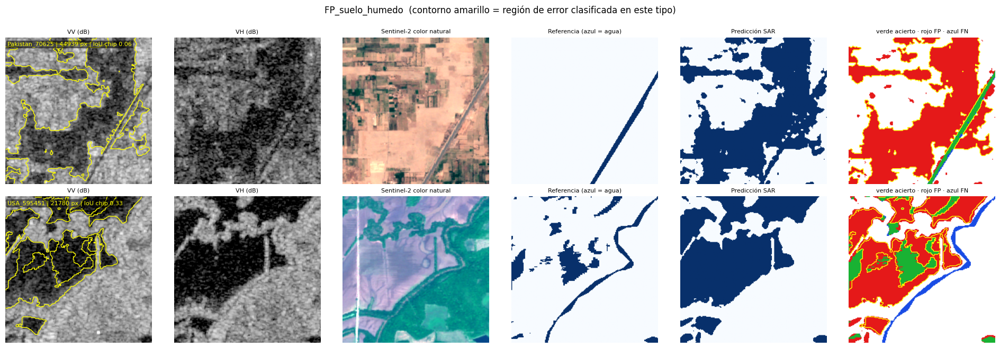

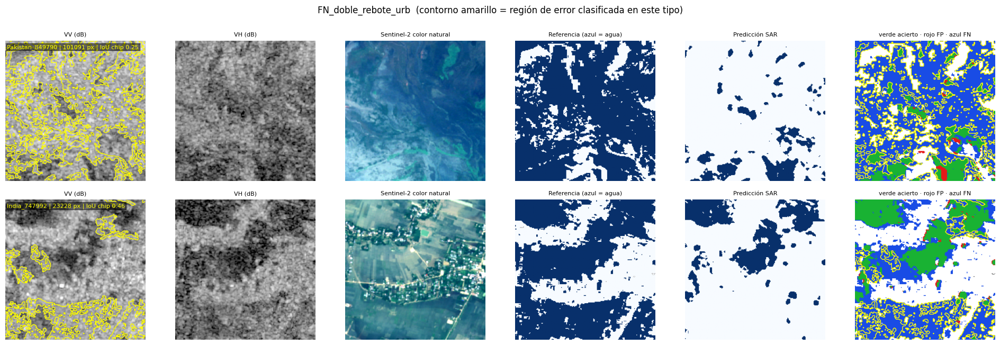

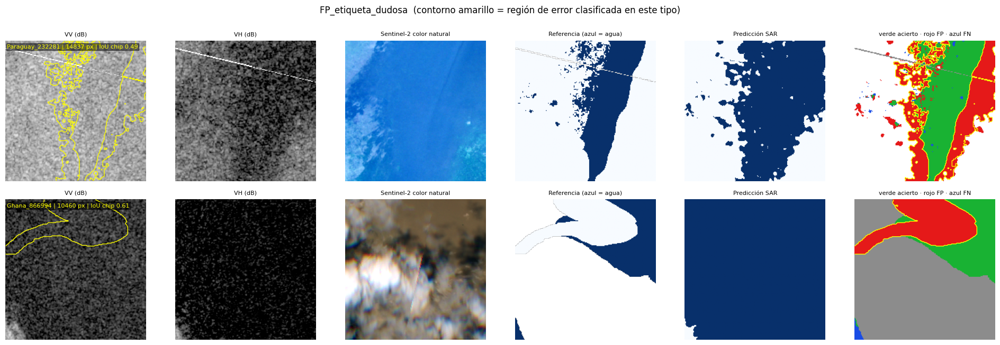

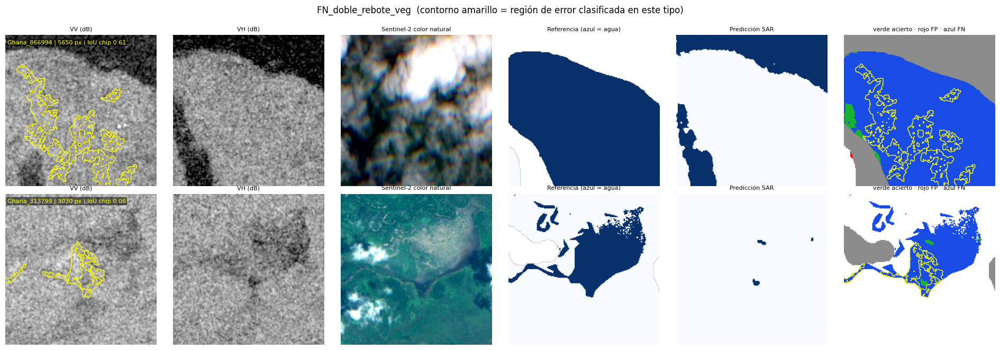

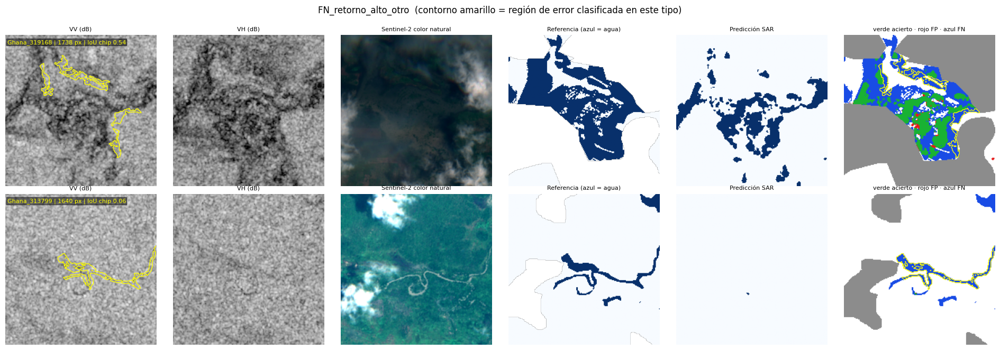

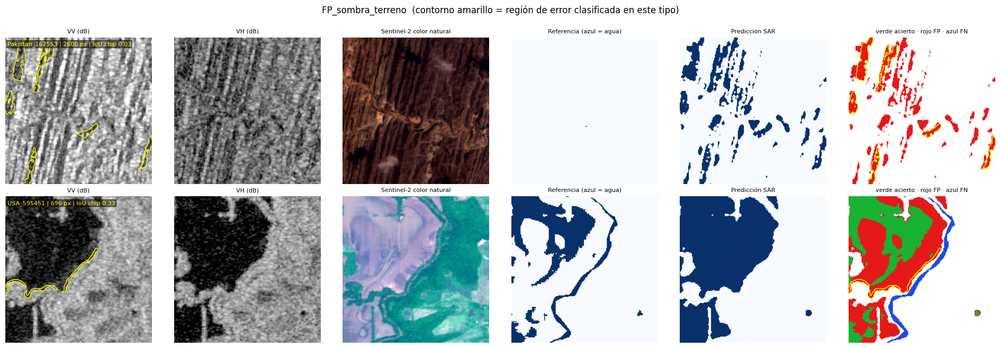

In [ ]:
# ===== Ejemplos visuales concretos por tipo de error (2 mejores chips por tipo) =====
def err_map(pred, y, v):
    e = np.ones(pred.shape + (3,), np.float32)
    e[y & pred] = (0.1, 0.7, 0.2); e[~y & pred] = (0.9, 0.1, 0.1); e[y & ~pred] = (0.1, 0.3, 0.9); e[~v] = 0.55
    return e

def panel_rows(t, n_ex=2, win=192):
    exs = EX[t][:n_ex]
    fig, ax = plt.subplots(len(exs), 6, figsize=(19, 3.3 * len(exs)), squeeze=False)
    for r, (n, split, i, m) in enumerate(exs):
        it = sp[split][i]; P, Y, V = get_pred(best_name, split)
        with rasterio.open(it['s1']) as d: s1 = d.read().astype(np.float32)
        s2 = fd.read_s2(fd.s2_path(it['s1']))
        pred, y, v = P[i].astype(np.float32) > 0.5, Y[i].astype(bool), V[i]
        r0, r1, c0, c1 = fd.crop_around(m, win); sl = (slice(r0, r1), slice(c0, c1))
        iou = (pred & y & v).sum() / max(1, ((pred | y) & v).sum())
        panels = [(s1[0][sl], 'VV (dB)', dict(cmap='gray', vmin=-25, vmax=0)),
                  (s1[1][sl], 'VH (dB)', dict(cmap='gray', vmin=-30, vmax=-5)),
                  (fd.rgb_stretch(s2)[sl], 'Sentinel-2 color natural', {}),
                  (np.ma.masked_where(~v[sl], y[sl]), 'Referencia (azul = agua)', dict(cmap='Blues', vmin=0, vmax=1)),
                  (pred[sl], 'Predicción SAR', dict(cmap='Blues', vmin=0, vmax=1)),
                  (err_map(pred, y, v)[sl], 'verde acierto · rojo FP · azul FN', {})]
        for a, (img, ttl, kw) in zip(ax[r], panels):
            a.imshow(img, **kw); a.set_title(ttl, fontsize=8); a.axis('off')
            if ttl.startswith('verde') or ttl.startswith('VV'):
                a.contour(m[sl].astype(float), [0.5], colors='yellow', linewidths=1)
        ax[r, 0].text(2, 10, f"{it['name'][:-11]} | {n} px | IoU chip {iou:.2f}", color='yellow', fontsize=8,
                      bbox=dict(facecolor='black', alpha=.5, pad=1))
    plt.suptitle(f'{t}  (contorno amarillo = región de error clasificada en este tipo)', y=1.0)
    plt.tight_layout(); plt.savefig(f'{RES}/fallos_{t}.png', dpi=170, bbox_inches='tight'); plt.show()

for t in sorted(EX, key=lambda k: -PX[k]):
    panel_rows(t)

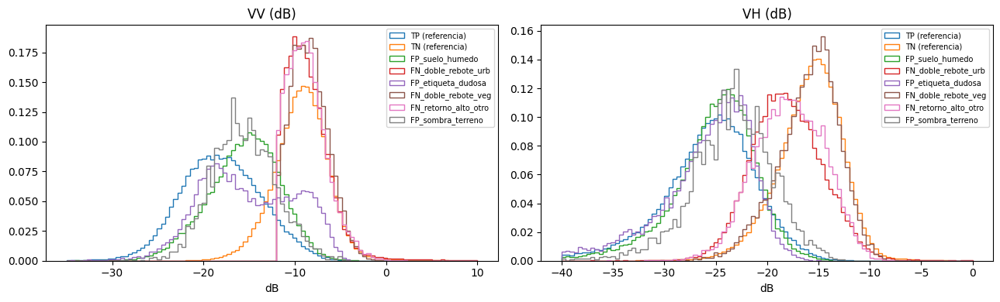

In [ ]:
# ===== Firma de retrodispersión de cada tipo frente a los aciertos (TP agua / TN no agua) =====
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, (b, nm, rg) in zip(ax, (('vv', 'VV', (-35, 10)), ('vh', 'VH', (-40, 0)))):
    for k in ('TP', 'TN'):
        a.hist(np.concatenate(REF[k][b]), 100, range=rg, density=True, histtype='step', lw=2, ls='--', label=f'{k} (referencia)')
    for t in sorted(SIG, key=lambda k: -PX[k]):
        a.hist(np.concatenate(SIG[t][b]), 100, range=rg, density=True, histtype='step', label=t)
    a.set_title(f'{nm} (dB)'); a.set_xlabel('dB'); a.legend(fontsize=7)
plt.tight_layout(); plt.savefig(f'{RES}/fallos_firmas_retrodispersion.png', dpi=170); plt.show()

### Cómo redactar la explicación (completar con las cifras de `err_summary` y los paneles)

Para **cada** tipo con presencia real en `err_summary`, el informe debe incluir: (1) la figura `fallos_<tipo>.png`, (2) las cifras (% del FP/FN total, VV/VH/NDVI/pendiente medianos) y (3) el mecanismo físico:

- **Sombra de radar / pendiente (`FP_sombra_terreno`).** El radar mira de lado; una vertiente cuya inclinación hacia el lado opuesto al sensor supera aproximadamente 90° − ángulo de incidencia no recibe señal (sombra), y las vertientes “de espaldas” devuelven muy poca energía. El píxel queda tan oscuro como el agua calma en VV y VH, y la U-Net —que solo ve VV/VH— no tiene cómo distinguirlo. *Qué mirar:* pendiente mediana alta, bordes nítidos alineados con el relieve, el óptico muestra suelo/vegetación, VH muy bajo. *Mitigación:* añadir DEM/pendiente o máscara HAND, usar órbita ascendente + descendente.
- **Doble rebote (`FN_doble_rebote_urb`, `FN_doble_rebote_veg`).** El agua bajo estructuras verticales (edificios, troncos) forma un reflector de esquina: la señal rebota agua → pared → sensor y la retrodispersión **sube** (VV > −12 dB) en vez de bajar. El modelo aprendió “agua = oscuro” y la omite. *Qué mirar:* referencia = agua pero VV/VH altos; NDVI bajo (urbano) o alto (vegetación). *Mitigación:* canales de coherencia/diferencia multitemporal (imagen pre-evento), polarimetría.
- **Suelo húmedo o superficie lisa (`FP_suelo_humedo`).** Campos arados, arena, asfalto o suelo saturado son rugosos a escala menor que la longitud de onda (≈5,6 cm, banda C) y reflejan de forma especular o absorben: retrodispersión baja que se **solapa** con la del agua (histogramas del notebook 01, sec. 6). *Qué mirar:* terreno llano, MNDWI < 0, VV ligeramente por encima del agua real (−22…−15 dB).
- **Etiqueta dudosa (`FP_etiqueta_dudosa`).** Si el óptico muestra agua donde la referencia dice “no agua”, el “error” puede ser de la anotación (agua pequeña o canales no marcados). Se reporta aparte para **no atribuir al SAR** fallos que no lo son.

> Escribe como hallazgo solo lo que muestren las cifras y los paneles; el resto, como hipótesis.

---
## ENTREGABLE 6 · Fusión SAR + óptico (Sentinel-2) frente a solo-SAR

**Diseño controlado (misma muestra, misma arquitectura, misma semilla):**

1. Un chip es **libre de nubes** si la fracción de píxeles marcados por la máscara heurística `fd.cloud_mask_s2` es ≤ `MAX_CLOUD` (Sen1Floods11 no trae máscara de nubes; se revisa visualmente en la celda de control).
2. Se entrenan **dos U-Net idénticas** (`depth=4`, BCE+Dice, mismas épocas/LR que E1) sobre **los mismos chips de train libres de nubes**: `sar` (2 canales) y `fusion` (2 + bandas S2 estandarizadas). Se evalúan sobre los mismos chips libres de nubes de val/test/Bolivia.
3. 3 semillas por modelo; diferencia **pareada** ΔIoU = IoU(fusión) − IoU(SAR) por semilla y **bootstrap sobre chips** para el IC95 de Δ.
4. Referencia adicional: E1 original (entrenado con los 252 chips) evaluado en el mismo subconjunto.

**Cautelas que deben ir al informe:** (a) las etiquetas doradas se anotaron **mirando S2**, así que el óptico contiene información muy cercana a la etiqueta: la mejora medida es una **cota optimista** de lo que ocurriría con etiquetas independientes; (b) el subconjunto sin nubes es más pequeño y puede ser más fácil; (c) en caso de nubes (típico en inundaciones) la fusión no está disponible: el valor práctico de SAR es justamente ese.

,chips totales,libres de nubes (<= 2%)
train,252,79
val,89,30
test,90,33
bolivia,15,3


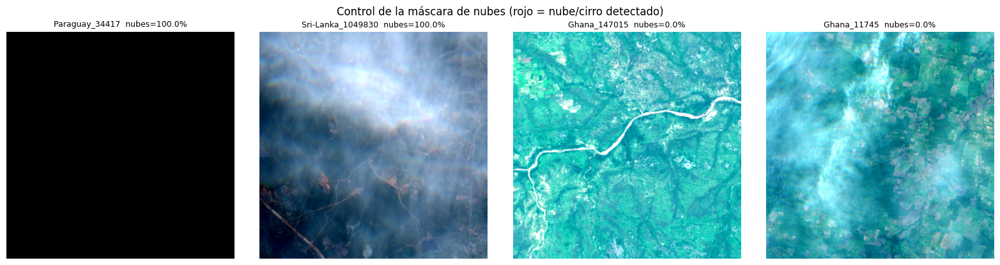

In [ ]:
# ===== Parámetros y chips libres de nubes =====
BANDS     = ['B2', 'B3', 'B4', 'B8', 'B11', 'B12']   # azul, verde, rojo, NIR, SWIR1, SWIR2  (mod. si se quiere otra combinación)
MAX_CLOUD = 0.02                                       # fracción máxima de píxeles nubosos por chip
SEEDS_F   = [0, 1, 2]
from torch.utils.data import DataLoader

CF_F = f'{RES}/cloud_frac.json'
cf = json.load(open(CF_F)) if os.path.exists(CF_F) else {}
for it in ALL_ITEMS:
    if it['name'] not in cf:
        cf[it['name']] = fd.cloud_fraction(fd.s2_path(it['s1']))
json.dump(cf, open(CF_F, 'w'))
elig = {k: [it for it in sp[k] if cf[it['name']] <= MAX_CLOUD] for k in sp}
tbl = pd.DataFrame({k: {'chips totales': len(sp[k]), f'libres de nubes (<= {MAX_CLOUD:.0%})': len(elig[k])} for k in sp}).T
display(tbl); tbl.to_csv(f'{RES}/entregable6_chips_libres_de_nubes.csv')
assert len(elig['train']) >= 30 and len(elig['val']) >= 5 and len(elig['test']) >= 5, \
    'Muy pocos chips libres de nubes: sube MAX_CLOUD o revisa la máscara (celda de control de abajo).'

# --- control visual de la máscara de nubes: 2 chips más nubosos y 2 más limpios ---
ordered = sorted(ALL_ITEMS, key=lambda it: cf[it['name']])
show = ordered[-2:] + ordered[:2]
fig, ax = plt.subplots(1, 4, figsize=(16, 4.2))
for a, it in zip(ax, show):
    r = fd.read_s2(fd.s2_path(it['s1'])); a.imshow(fd.rgb_stretch(r))
    a.contour(fd.cloud_mask_s2(r).astype(float), [0.5], colors='red', linewidths=.8)
    a.set_title(f"{it['name'][:-11]}  nubes={cf[it['name']]:.1%}", fontsize=9); a.axis('off')
plt.suptitle('Control de la máscara de nubes (rojo = nube/cirro detectado)'); plt.tight_layout(); plt.show()

In [ ]:
# ===== Entrenamiento controlado: solo-SAR vs SAR+S2 (mismos chips de train libres de nubes) =====
mean_s2, std_s2 = fd.s2_stats(elig['train'], BANDS)
print('S2 media:', dict(zip(BANDS, mean_s2.round(3))), '\nS2 desvío:', dict(zip(BANDS, std_s2.round(3))))

def mk_ds(items, mode, train=False):
    return fd.FusionDataset(items, mode=mode, bands=BANDS, mean=mean_s2, std=std_s2,
                            crop=CROP if train else None, augment=train)
def mk_loader(items, mode): return DataLoader(mk_ds(items, mode), batch_size=8, shuffle=False, num_workers=2)
LOADF = {(m, k): mk_loader(elig[k], m) for m in ('sar', 'fusion') for k in ('val', 'test', 'bolivia')}

def run_fusion(mode, seed):
    tag = f'FUS_{mode}_c{int(MAX_CLOUD * 1000):03d}_nb{len(BANDS)}_s{seed}'
    ckpt, hist_f = f'{CKPT}/{tag}.pt', f'{RES}/hist_{tag}.json'
    set_seed(seed)
    model = UNet(in_ch=2 + (len(BANDS) if mode == 'fusion' else 0)).to(device)
    if os.path.exists(ckpt) and os.path.exists(hist_f) and not RETRAIN:
        model.load_state_dict(torch.load(ckpt, map_location=device)); return model
    hist, _ = train_model(model, mk_ds(elig['train'], mode, train=True), LOADF[(mode, 'val')], device,
                          EP_HAND, 1e-3, ckpt=ckpt, verbose=False)
    json.dump(hist, open(hist_f, 'w'))
    return model

CNT = {}          # (modelo, semilla, partición) -> conteos por chip (N,4) = [TP,FP,FN,TN]
for mode in ('sar', 'fusion'):
    for seed in SEEDS_F:
        m = run_fusion(mode, seed)
        for k in ('val', 'test', 'bolivia'):
            P, Y, V = predict(m, LOADF[(mode, k)], device)
            CNT[(mode, seed, k)] = per_chip_counts(P, Y, V)
        print(f"{mode:6s} s{seed}: val IoU {metrics_from_counts(CNT[(mode, seed, 'val')].sum(0))['iou']:.4f} | "
              f"test IoU {metrics_from_counts(CNT[(mode, seed, 'test')].sum(0))['iou']:.4f} | "
              f"bolivia IoU {metrics_from_counts(CNT[(mode, seed, 'bolivia')].sum(0))['iou']:.4f}")
        del m
# referencia: E1 original (252 chips de train, solo SAR) en el mismo subconjunto libre de nubes
m1 = UNet(in_ch=2).to(device); m1.load_state_dict(torch.load(f'{CKPT}/E1_hand.pt', map_location=device))
for k in ('val', 'test', 'bolivia'):
    P, Y, V = predict(m1, LOADF[('sar', k)], device); CNT[('E1_original', 0, k)] = per_chip_counts(P, Y, V)
del m1

S2 media: {'B2': np.float32(0.109), 'B3': np.float32(0.106), 'B4': np.float32(0.083), 'B8': np.float32(0.248), 'B11': np.float32(0.181), 'B12': np.float32(0.092)} 
S2 desvío: {'B2': np.float32(0.017), 'B3': np.float32(0.02), 'B4': np.float32(0.03), 'B8': np.float32(0.084), 'B11': np.float32(0.07), 'B12': np.float32(0.048)}
sar    s0: val IoU 0.4953 | test IoU 0.5275 | bolivia IoU 0.2254
sar    s1: val IoU 0.5092 | test IoU 0.5231 | bolivia IoU 0.2401
sar    s2: val IoU 0.4978 | test IoU 0.5226 | bolivia IoU 0.1824
fusion s0: val IoU 0.7575 | test IoU 0.8110 | bolivia IoU 0.4431
fusion s1: val IoU 0.7602 | test IoU 0.7966 | bolivia IoU 0.4561
fusion s2: val IoU 0.7566 | test IoU 0.8000 | bolivia IoU 0.4180


,modelo,n_semillas,val_iou,val_iou_sd,test_iou,test_iou_sd,test_f1,test_omission,test_commission,bolivia_iou,bolivia_iou_sd
0,"E1 original (252 chips, solo SAR)",1,0.4774,NaN,0.5585,NaN,0.7168,0.3378,0.2189,0.2322,NaN
1,Solo-SAR (chips sin nubes),3,0.5008,0.0075,0.5244,0.0027,0.6880,0.3506,0.2685,0.2160,0.0300
2,SAR + S2 (6 bandas),3,0.7581,0.0019,0.8025,0.0075,0.8904,0.1162,0.1026,0.4391,0.0194



== ΔIoU = IoU(fusión) − IoU(solo-SAR), pareado por semilla ==


,particion,chips,dIoU_medio,dIoU_sd_semillas,dIoU_por_semilla,IC95_bootstrap,veredicto
0,val,30,0.2573,0.0058,"[0.2622, 0.251, 0.2588]","[+0.1249, +0.3961]",MEJORA
1,test,33,0.2781,0.0050,"[0.2835, 0.2735, 0.2775]","[+0.1214, +0.4342]",MEJORA
2,bolivia,3,0.2231,0.0109,"[0.2176, 0.216, 0.2356]","[+0.0375, +0.2570]",MEJORA


Bootstrap sobre chips (los chips de un mismo evento no son independientes: el IC es optimista). Bolivia tiene muy pocos chips libres de nubes: interpretar con cautela.


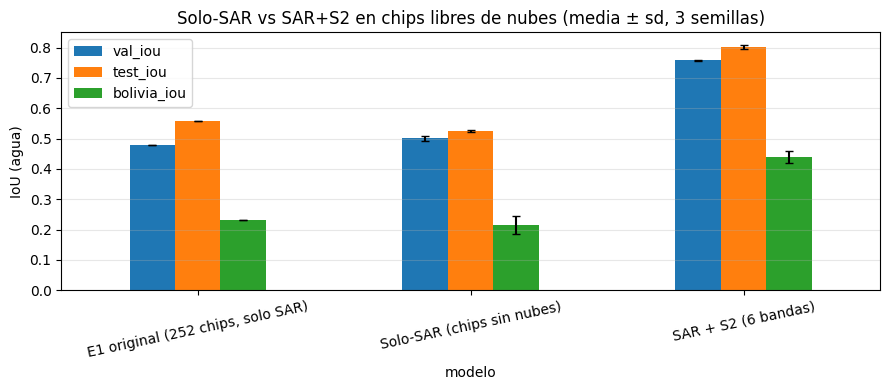

In [ ]:
# ===== Resultados: media ± sd por semilla, Δ pareado e IC95 bootstrap =====
def met(c): return metrics_from_counts(c.sum(0))
rows = []
for mode, lab in (('E1_original', 'E1 original (252 chips, solo SAR)'), ('sar', 'Solo-SAR (chips sin nubes)'),
                  ('fusion', f'SAR + S2 ({len(BANDS)} bandas)')):
    seeds = [0] if mode == 'E1_original' else SEEDS_F
    row = dict(modelo=lab, n_semillas=len(seeds))
    for k in ('val', 'test', 'bolivia'):
        ms = [met(CNT[(mode, s, k)]) for s in seeds]
        for q in ('iou', 'f1', 'omission', 'commission'):
            v = np.array([x[q] for x in ms]); row[f'{k}_{q}'] = v.mean(); row[f'{k}_{q}_sd'] = v.std(ddof=1) if len(v) > 1 else np.nan
    rows.append(row)
fres = pd.DataFrame(rows); fres.to_csv(f'{RES}/entregable6_fusion_resultados.csv', index=False)
display(fres[['modelo', 'n_semillas', 'val_iou', 'val_iou_sd', 'test_iou', 'test_iou_sd', 'test_f1', 'test_omission', 'test_commission',
              'bolivia_iou', 'bolivia_iou_sd']].round(4))

print('\n== ΔIoU = IoU(fusión) − IoU(solo-SAR), pareado por semilla ==')
B, rngb = 2000, np.random.default_rng(0); drows = []
for k in ('val', 'test', 'bolivia'):
    d = np.array([met(CNT[('fusion', s, k)])['iou'] - met(CNT[('sar', s, k)])['iou'] for s in SEEDS_F])
    Cs = sum(CNT[('sar', s, k)] for s in SEEDS_F); Cf = sum(CNT[('fusion', s, k)] for s in SEEDS_F); n = len(Cs)
    boot = [met(Cf[ii])['iou'] - met(Cs[ii])['iou'] for ii in (rngb.integers(0, n, n) for _ in range(B))]
    lo, hi = np.percentile(boot, [2.5, 97.5])
    drows.append(dict(particion=k, chips=n, dIoU_medio=d.mean(), dIoU_sd_semillas=d.std(ddof=1), dIoU_por_semilla=np.round(d, 4).tolist(),
                      IC95_bootstrap=f'[{lo:+.4f}, {hi:+.4f}]', veredicto=('MEJORA' if lo > 0 else 'EMPEORA' if hi < 0 else 'sin evidencia de diferencia')))
dtab = pd.DataFrame(drows); dtab.to_csv(f'{RES}/entregable6_delta_iou.csv', index=False); display(dtab.round(4))
print('Bootstrap sobre chips (los chips de un mismo evento no son independientes: el IC es optimista). '
      'Bolivia tiene muy pocos chips libres de nubes: interpretar con cautela.')

ax = fres.set_index('modelo')[['val_iou', 'test_iou', 'bolivia_iou']].plot.bar(
    yerr=fres.set_index('modelo')[['val_iou_sd', 'test_iou_sd', 'bolivia_iou_sd']].fillna(0).values.T, figsize=(9, 4), rot=12, capsize=3)
ax.set_ylabel('IoU (agua)'); ax.set_title('Solo-SAR vs SAR+S2 en chips libres de nubes (media ± sd, 3 semillas)'); ax.grid(axis='y', alpha=.3)
plt.tight_layout(); plt.savefig(f'{RES}/entregable6_fusion_barras.png', dpi=170); plt.show()

,evento,chips,IoU_SAR,IoU_fusion,dIoU
2,Mekong,3,0.893,0.955,0.062
5,Somalia,1,0.571,0.725,0.153
1,India,3,0.485,0.689,0.203
0,Ghana,7,0.266,0.471,0.205
4,Paraguay,7,0.479,0.710,0.231
7,USA,9,0.547,0.823,0.276
6,Sri-Lanka,2,0.168,0.569,0.401
3,Pakistan,1,0.239,0.832,0.594


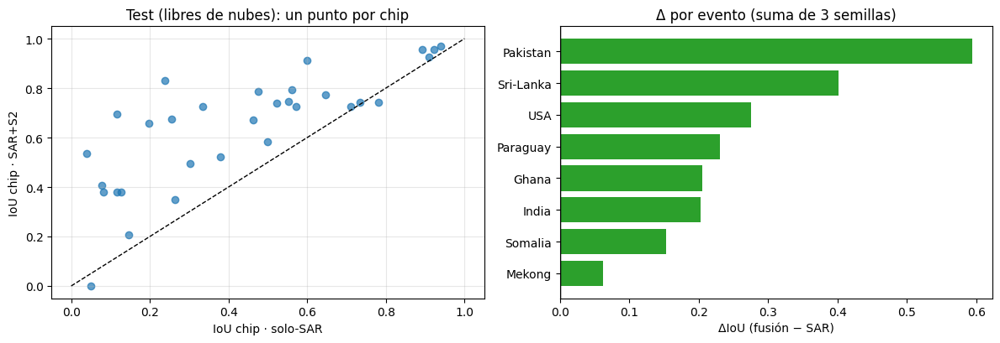

In [ ]:
# ===== ¿Dónde mejora la fusión? IoU por chip (test) y Δ por evento =====
def chip_iou(C): tp, fp, fn = C[:, 0], C[:, 1], C[:, 2]; den = tp + fp + fn; return np.where(den > 0, tp / np.maximum(den, 1), np.nan)
Cs = sum(CNT[('sar', s, 'test')] for s in SEEDS_F); Cf = sum(CNT[('fusion', s, 'test')] for s in SEEDS_F)
ev = np.array([country(it['name']) for it in elig['test']])
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].scatter(chip_iou(Cs), chip_iou(Cf), c='tab:blue', alpha=.7); ax[0].plot([0, 1], [0, 1], 'k--', lw=1)
ax[0].set_xlabel('IoU chip · solo-SAR'); ax[0].set_ylabel('IoU chip · SAR+S2'); ax[0].set_title('Test (libres de nubes): un punto por chip'); ax[0].grid(alpha=.3)
ev_rows = [dict(evento=e, chips=int((ev == e).sum()), IoU_SAR=met(Cs[ev == e])['iou'], IoU_fusion=met(Cf[ev == e])['iou'],
                dIoU=met(Cf[ev == e])['iou'] - met(Cs[ev == e])['iou']) for e in sorted(set(ev))]
evt = pd.DataFrame(ev_rows).sort_values('dIoU'); display(evt.round(3)); evt.to_csv(f'{RES}/entregable6_delta_por_evento.csv', index=False)
ax[1].barh(evt.evento, evt.dIoU, color=np.where(evt.dIoU >= 0, 'tab:green', 'tab:red')); ax[1].axvline(0, color='k', lw=1)
ax[1].set_xlabel('ΔIoU (fusión − SAR)'); ax[1].set_title('Δ por evento (suma de 3 semillas)')
plt.tight_layout(); plt.savefig(f'{RES}/entregable6_fusion_por_chip_y_evento.png', dpi=170); plt.show()